![Logo Javeriana](https://images.seeklogo.com/logo-png/11/1/pontificia-universidad-javeriana-logo-png_seeklogo-110703.png)

## Nombres:
- Gabriel Jaramillo Cuberos (Id: 20529022)
- David Vargas (Id: 20485686)
- Juan Felipe Gómez López (Id: 20553416)
- Sara Pulgarín (Id: 20491129)
- Juan Camilo Delgado (Id: 20506996)

*Materia:* Procesamiento de Datos (1255)  |  *Tema:* Consultoría Nueva York

*Descripción:* Análisis territorial que relaciona los indicadores de pobreza y educación (PUMS, personas de 25 años o más, ponderadas con `PWGTP`) con los indicadores de seguridad disponibles (arrestos NYPD 2018), y mide cómo cambia la lectura de seguridad al normalizar por población (tasas por 100.000 habitantes).
 
*Nombre del fichero:* Pobreza_Educacion_Seguridad_P7-P8.ipynb
 
# Pobreza, educación y seguridad en Nueva York 2018 — Correlaciones territoriales y normalización por población
 
## Objetivos del cuaderno
 
Responder, con evidencia descriptiva y cálculos auditables, las dos preguntas del componente de integración:
 
7. ¿Cómo se relacionan los indicadores territoriales de pobreza y educación con los indicadores de seguridad disponibles?
8. ¿Cómo cambian los indicadores territoriales de seguridad cuando se normalizan por población?
 
Objetivos específicos:
 
- Reconstruir los indicadores de seguridad por borough con el dataset de arrestos **actualizado** (año 2018 completo).
- Consumir los resúmenes de pobreza/educación (cuaderno 03) y la población 2018 (scraper) sin recalcularlos.
- Construir una **tabla territorial integrada** (una fila por borough) con población, pobreza, educación y seguridad.
- Medir la asociación con Pearson, Spearman, prueba de permutación exacta y sensibilidad *leave-one-out*.
- Comparar conteos absolutos contra tasas por 100.000 habitantes (rankings, participación, correlaciones y robustez del denominador).
- Generar tablas, gráficas y archivos de salida para el documento final.
 
## Diseño del análisis (decisiones y limitaciones)
 
1. **Unidad de análisis: el borough (n = 5).** Es el único nivel territorial común a pobreza, educación, población y arrestos. Con cinco observaciones, cualquier coeficiente de correlación es frágil; por eso se reportan prueba de permutación exacta (5! = 120 reordenamientos) y *leave-one-out*, y los resultados se presentan como **descriptivos, no inferenciales**.
2. **Seguridad = arrestos, no delitos.** Un arresto refleja la actividad policial además de la incidencia delictiva, y no equivale a una persona única. Los siniestros viales (cuaderno 02) no traen borough, así que no pueden entrar a un análisis territorial.
3. **Indicadores de seguridad.** Total de arrestos; por gravedad legal (`felony`, `misdemeanor`); por grupo de delito (violentos, drogas, armas, propiedad), definidos con patrones sobre `ofns_desc` y auditados celda a celda; y el porcentaje de arrestos `felony` (indicador de composición, independiente del tamaño poblacional).
4. **Pobreza y educación.** Se toman del resumen del cuaderno 03 (PUMS, personas de 25 años o más, ponderadas con `PWGTP`). Este cuaderno **no recalcula** esos filtros; solo los consume y documenta su procedencia.
5. **Población.** Población residente 2018 por borough obtenida en el scraper (cuaderno 05). Las tasas son anuales.
6. **Año.** 2018 completo (se verifica cobertura enero–diciembre).
7. **Limitaciones.** Falacia ecológica (una relación entre agregados no implica una relación entre individuos); correlación no es causalidad; el denominador residente no recoge población flotante (especialmente en Manhattan); los indicadores de PUMS son estimaciones muestrales con error; se hacen múltiples comparaciones con n = 5, por lo que algunos coeficientes altos pueden aparecer por azar.
 
## Metodología
 
Reconstrucción de indicadores de arrestos en Spark → agregación por borough → unión con pobreza, educación y población en una tabla de cinco filas → análisis de correlación y de normalización en pandas → tablas, gráficas y exportación.
 
Filtros y transformaciones que quedarían documentados
 
Filtros
1. Fechas válidas dentro de 2018.
2. Borough válido (B, K, M, Q, S).
3. Población del año 2018.
 
Transformaciones
1. Parseo de fecha y traducción de códigos de borough.
2. Clasificación de `ofns_desc` en grupos de delito (patrones auditados).
3. Conteo por borough con `COUNT(DISTINCT arrest_key)`.
4. Unión territorial con pobreza, educación y población (validada 1 a 1).
5. Cálculo de tasas por 100.000 habitantes y de participaciones porcentuales.
6. Correlaciones (Pearson, Spearman), p-valores por permutación exacta y sensibilidad *leave-one-out*.


## Insumos y relación con los demás cuadernos
 
| Insumo | Origen | Uso en este cuaderno | Observación |
|---|---|---|---|
| Arrestos 2018 | `NYPD_Arrests_Data_2018.csv` (dataset actualizado) | Indicadores de seguridad por borough | Se recalcula aquí. **No** se usa `arrestos_resumen.json` de la Entrega 1: se generó con el dataset anterior, que solo cubría diciembre. |
| Pobreza y educación | `pobreza_resumen.json` (cuaderno 03, PUMS, `PWGTP`, edad ≥ 25) | Indicadores socioeconómicos por borough | Se carga con `p.cargar_resumen`, que valida que la fuente no haya cambiado. |
| Población 2018 | `poblacion_nyc_2018.csv` (cuaderno 05, scraper) | Denominador de las tasas | Si el archivo no existe se usa la misma población que el cuaderno P1-P2. |
| Vehículos y accidentes | Cuaderno 02 | **No se usa** | No tiene borough en los datos disponibles; no permite análisis territorial. |


In [1]:
import sys
import glob
import json
import warnings
from pathlib import Path
 
SPARK_PY = "/opt/cluster/spark/python"
sys.path.insert(0, SPARK_PY)
for z in glob.glob(f"{SPARK_PY}/lib/*.zip"):
    sys.path.insert(0, z)
 
import pyspark
print("PySpark:", pyspark.__version__, pyspark.__file__)
 
sys.path.insert(0, "/opt/cluster/Proyecto/Entrega_1/cuadernos")
 
from Utils import proyecto as p
from pyspark.sql import functions as F
 
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from itertools import permutations
from IPython.display import display, Markdown
 
# La carpeta de resultados de la Entrega 1 se guarda ANTES de redirigir p.RESULTADOS:
# de ahí se leen los resúmenes de pobreza y la población.
# Ruta de resultados de la Entrega 1 (insumos)
RESULTADOS_E1 = Path(
    "/opt/cluster/Proyecto/Entrega_2/seguridad_publica/resultados_arrestos_P1-2"
)

# Ruta de resultados de este cuaderno (Entrega 2)
RESULTADOS_P78 = Path(
    "/opt/cluster/Proyecto/Entrega_2/seguridad_socioeconomica/resultados_pobreza_seguridad_P7-8"
)

RESULTADOS_P78.mkdir(parents=True, exist_ok=True)

# Redirigir los resultados del módulo a la nueva carpeta
p.RESULTADOS = RESULTADOS_P78

ANIO = 2018
spark = p.iniciar_spark("Entrega2_Pobreza_Educacion_Seguridad_P7_P8")

print("Dataset:", p.DATA_DIR)
print("Resultados Entrega 1 (insumos):", RESULTADOS_E1)
print("Resultados de este cuaderno:", p.RESULTADOS)

PySpark: 4.2.0 /opt/cluster/spark/python/lib/pyspark.zip/pyspark/__init__.py


Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
/opt/cluster/spark/python/lib/pyspark.zip/pyspark/testing/utils.py:127: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
26/11/14 13:00:01 WARN Utils: Service 'SparkUI' could not bind on port 4040. Attempting port 4041.


Python: 3.11.13 | PySpark: 4.2.0 | Spark: 4.2.0
Ejecutable: /home/estudiante/jupyter_env/bin/python3.11
Aplicación: app-20261114125732-0094 | Máximo de núcleos: 2
Los recursos físicos del cluster deben documentarse desde la interfaz del master.
Dataset: /opt/cluster/Proyecto/Entrega_1/datasets
Resultados Entrega 1 (insumos): /opt/cluster/Proyecto/Entrega_2/seguridad_publica/resultados_arrestos_P1-2
Resultados de este cuaderno: /opt/cluster/Proyecto/Entrega_2/seguridad_socioeconomica/resultados_pobreza_seguridad_P7-8


# 1. Indicadores de seguridad por borough (arrestos 2018)
 
Se lee el dataset actualizado, se parsea la fecha, se traduce el código de borough y se verifica el inventario antes de agregar. La verificación debe coincidir con la del cuaderno P1-P2: **246.773 filas, 246.773 claves únicas, fechas del 2018-01-01 al 2018-12-31**.

In [ ]:
ARCHIVO_ARRESTOS = "NYPD_Arrests_Data_2018.csv"
BORO_NOMBRES = {"B": "Bronx", "K": "Brooklyn", "M": "Manhattan", "Q": "Queens", "S": "Staten Island"}
 
df_crudo = p.leer_csv(spark, ARCHIVO_ARRESTOS, ["arrest_key", "arrest_date"])
 
base = (
    df_crudo
    .withColumn("fecha", F.to_date("arrest_date", "MM/dd/yyyy"))
    .withColumn("boro_cod", F.upper(p.texto("arrest_boro")))
    .withColumn("ofns", F.upper(p.texto("ofns_desc")))
    .withColumn("law_cat", F.upper(p.texto("law_cat_cd")))
    .withColumn(
        "borough",
        F.coalesce(*[F.when(F.col("boro_cod") == c, n) for c, n in BORO_NOMBRES.items()])
    )
)
 
print("Inventario del dataset:")
base.agg(
    F.count("*").alias("filas"),
    F.countDistinct("arrest_key").alias("claves_unicas"),
    F.min("fecha").alias("fecha_min"),
    F.max("fecha").alias("fecha_max"),
    F.sum(F.col("fecha").isNull().cast("int")).alias("fechas_nulas"),
    F.sum(F.col("borough").isNull().cast("int")).alias("borough_no_reconocido"),
).show(truncate=False)
 
print("Cobertura mensual (debe haber 12 meses):")
base.groupBy(F.month("fecha").alias("mes")).count().orderBy("mes").show(12)
 
arrestos_2018 = base.filter((F.year("fecha") == ANIO) & F.col("borough").isNotNull()).cache()
print("Filas después de filtrar 2018 y borough válido:", arrestos_2018.count())

26/11/14 13:02:38 WARN TaskSchedulerImpl: Initial job has not accepted any resources; check your cluster UI to ensure that workers are registered and have sufficient resources
26/11/14 13:02:53 WARN TaskSchedulerImpl: Initial job has not accepted any resources; check your cluster UI to ensure that workers are registered and have sufficient resources


**Lectura.** El filtro conserva solo arrestos con fecha de 2018 y borough reconocido (B, K, M, Q, S). Como las cifras del inventario coinciden con el cuaderno P1-P2, la base de este cuaderno es la misma y los resultados son comparables entre ambos. El conteo por mes confirma que ya no estamos ante el dataset anterior, que solo traía diciembre.

## Grupos de delito usados como indicadores de seguridad
 
`ofns_desc` tiene 70 categorías y el top 10 cubre apenas 71 % de los arrestos. Para no depender solo de las diez más frecuentes, los grupos se definen con **patrones sobre el texto de `ofns_desc`**:
 
| Grupo | Patrón | Qué recoge |
|---|---|---|
| `violentos` | `ASSAULT`, `ROBBERY`, `MURDER`, `MANSLAUGHTER`, `RAPE`, `KIDNAPPING`, `HOMICIDE` | Delitos contra las personas |
| `drogas` | `DRUGS` | Sustancias controladas |
| `armas` | `WEAPONS` | Armas peligrosas |
| `propiedad` | `LARCENY`, `BURGLAR`, `MISCHIEF`, `STOLEN PROPERTY`, `THEFT` | Hurto, robo con escalamiento y daño a la propiedad |
 
La siguiente celda **audita** qué categorías cayeron en cada grupo y verifica que ningún arresto quede en dos grupos a la vez.

In [12]:
PATRONES_OFNS = {
    "violentos": "ASSAULT|ROBBERY|MURDER|MANSLAUGHTER|RAPE|KIDNAPPING|HOMICIDE",
    "drogas": "DRUGS",
    "armas": "WEAPONS",
    "propiedad": "LARCENY|BURGLAR|MISCHIEF|STOLEN PROPERTY|THEFT",
}
 
for grupo, patron in PATRONES_OFNS.items():
    detalle = (
        arrestos_2018.filter(F.col("ofns").rlike(patron))
        .groupBy("ofns").count().orderBy(F.desc("count"))
    )
    filas = [r.asDict() for r in detalle.collect()]
    total_grupo = sum(f["count"] for f in filas)
    print(f"\nGrupo '{grupo}' | patrón: {patron} | {len(filas)} categorías | {total_grupo} arrestos")
    display(pd.DataFrame(filas).rename(columns={"ofns": "ofns_desc", "count": "arrestos"}))
 
suma_marcas = sum(
    F.coalesce(F.col("ofns").rlike(pat).cast("int"), F.lit(0)) for pat in PATRONES_OFNS.values()
)
solapes = arrestos_2018.filter(suma_marcas > 1).count()
print("\nArrestos asignados a más de un grupo:", solapes)


Grupo 'violentos' | patrón: ASSAULT|ROBBERY|MURDER|MANSLAUGHTER|RAPE|KIDNAPPING|HOMICIDE | 9 categorías | 60322 arrestos


,ofns_desc,arrestos
0,ASSAULT 3 & RELATED OFFENSES,34318
1,FELONY ASSAULT,15193
2,ROBBERY,9024
3,MURDER & NON-NEGL. MANSLAUGHTER,852
4,RAPE,808
5,KIDNAPPING & RELATED OFFENSES,83
6,MURDER & NON-NEGL. MANSLAUGHTE,23
7,"HOMICIDE-NEGLIGENT,UNCLASSIFIED",17
8,HOMICIDE-NEGLIGENT-VEHICLE,4



Grupo 'drogas' | patrón: DRUGS | 1 categorías | 32594 arrestos


,ofns_desc,arrestos
0,DANGEROUS DRUGS,32594



Grupo 'armas' | patrón: WEAPONS | 1 categorías | 9636 arrestos


,ofns_desc,arrestos
0,DANGEROUS WEAPONS,9636



Grupo 'propiedad' | patrón: LARCENY|BURGLAR|MISCHIEF|STOLEN PROPERTY|THEFT | 11 categorías | 61296 arrestos


,ofns_desc,arrestos
0,PETIT LARCENY,23418
1,GRAND LARCENY,10419
2,CRIMINAL MISCHIEF & RELATED OFFENSES,10219
3,OTHER OFFENSES RELATED TO THEFT,7359
4,BURGLARY,4566
5,POSSESSION OF STOLEN PROPERTY,1349
6,POSSESSION OF STOLEN PROPERTY 5,1207
7,GRAND LARCENY OF MOTOR VEHICLE,1019
8,BURGLAR'S TOOLS,811
9,THEFT-FRAUD,523



Arrestos asignados a más de un grupo: 0


**Lectura.** Cada grupo muestra exactamente qué categorías de `ofns_desc` contiene, de modo que la definición sea trazable. Como el número de arrestos en más de un grupo es 0, los grupos son mutuamente excluyentes y pueden compararse sin doble conteo. Los grupos **no cubren todos los arrestos** (hay categorías como tránsito o "Miscellaneous Penal Law" fuera de ellos); por eso no se espera que sumen el total. El grupo `violentos` es una aproximación: recoge delitos contra las personas registrados como arresto, no la totalidad de la violencia del territorio.

In [13]:
def marca(patron):
    return F.when(F.col("ofns").rlike(patron), 1).otherwise(0)
 
agregado = arrestos_2018.groupBy("borough").agg(
    F.countDistinct("arrest_key").alias("arrestos"),
    F.sum(F.when(F.col("law_cat") == "F", 1).otherwise(0)).alias("arrestos_felony"),
    F.sum(F.when(F.col("law_cat") == "M", 1).otherwise(0)).alias("arrestos_misdemeanor"),
    F.sum(marca(PATRONES_OFNS["violentos"])).alias("arrestos_violentos"),
    F.sum(marca(PATRONES_OFNS["drogas"])).alias("arrestos_drogas"),
    F.sum(marca(PATRONES_OFNS["armas"])).alias("arrestos_armas"),
    F.sum(marca(PATRONES_OFNS["propiedad"])).alias("arrestos_propiedad"),
)
 
seg = pd.DataFrame([r.asDict() for r in agregado.collect()])
for c in seg.columns:
    if c != "borough":
        seg[c] = pd.to_numeric(seg[c])
 
# Verificación contra el cuaderno P1-P2 (conteos por borough ya validados allí)
ESPERADO_P12 = {"Brooklyn": 68405, "Manhattan": 62582, "Bronx": 55446, "Queens": 49916, "Staten Island": 10424}
verif = seg[["borough", "arrestos"]].copy()
verif["esperado_P1_P2"] = verif["borough"].map(ESPERADO_P12)
verif["coincide"] = verif["arrestos"] == verif["esperado_P1_P2"]
display(verif)
print("¿Todos los conteos coinciden con P1-P2?", bool(verif["coincide"].all()))
display(seg.sort_values("arrestos", ascending=False).reset_index(drop=True))

,borough,arrestos,esperado_P1_P2,coincide
0,Brooklyn,68405,68405,True
1,Staten Island,10424,10424,True
2,Manhattan,62582,62582,True
3,Queens,49916,49916,True
4,Bronx,55446,55446,True


¿Todos los conteos coinciden con P1-P2? True


,borough,arrestos,arrestos_felony,arrestos_misdemeanor,arrestos_violentos,arrestos_drogas,arrestos_armas,arrestos_propiedad
0,Brooklyn,68405,27126,39029,16746,9678,3209,15045
1,Manhattan,62582,20326,40761,11643,7488,1873,21952
2,Bronx,55446,17269,37562,16703,8788,2412,11015
3,Queens,49916,18297,30643,12960,4931,1816,10969
4,Staten Island,10424,3525,6800,2270,1709,326,2315


**Lectura.** La tabla de verificación compara el conteo por borough de este cuaderno con el del cuaderno P1-P2. Coincidir en los cinco distritos (Brooklyn 68.405, Manhattan 62.582, Bronx 55.446, Queens 49.916 y Staten Island 10.424). La segunda tabla son los **conteos absolutos** de cada indicador de seguridad; todavía no están normalizados y su orden está dominado por el tamaño de cada distrito.

# 2. Pobreza, educación y población
 
## 2.1 Resumen de pobreza y educación (cuaderno 03)
 
El cuaderno 03 ya aplica los filtros y transformaciones de PUMS (ponderación con `PWGTP` y población de 25 años o más) y exporta un resumen por borough. Aquí solo se **consume** ese resumen. La función `p.cargar_resumen` reconstruye la tabla y valida que el CSV fuente no haya cambiado desde que se exportó.

In [14]:
NOMBRE_RESUMEN_POBREZA = "pobreza_resumen.json"
 
# --- Ajuste manual opcional (dejar en None para autodetección) ---
COL_POBREZA_MANUAL = None          # ej.: "pobreza_pct"
COLS_EDUCACION_MANUAL = None       # ej.: ["educ_superior_pct"]
 
def cargar_resumen_entrega1(nombre):
    """Lee un resumen de la Entrega 1 apuntando temporalmente p.RESULTADOS a esa carpeta."""
    anterior = p.RESULTADOS
    p.RESULTADOS = RESULTADOS_E1
    try:
        return p.cargar_resumen(spark, nombre)
    finally:
        p.RESULTADOS = anterior
 
try:
    resultado = cargar_resumen_entrega1(NOMBRE_RESUMEN_POBREZA)
    df_spark, meta = (resultado if isinstance(resultado, tuple) else (resultado, None))
    pobreza_pd = pd.DataFrame([r.asDict() for r in df_spark.collect()])
    print("Metadatos del resumen:", meta)
except Exception as e:
    print("p.cargar_resumen falló (", type(e).__name__, "):", e)
    print("Se lee el JSON directamente.")
    with open(RESULTADOS_E1 / NOMBRE_RESUMEN_POBREZA, encoding="utf-8") as f:
        crudo = json.load(f)
    pobreza_pd = pd.DataFrame(crudo["datos"] if isinstance(crudo, dict) and "datos" in crudo else crudo)
 
pobreza_pd.columns = [str(c).strip() for c in pobreza_pd.columns]
print("\nColumnas del resumen:", list(pobreza_pd.columns))
display(pobreza_pd)

[Stage 55:>                                                         (0 + 2) / 2]

Metadatos del resumen: {'version': 1, 'anio_objetivo': 2018, 'estado': 'disponible', 'fuente': 'Pobreza_NY.csv', 'tamano_fuente': 22487106, 'modificacion_fuente_ns': 1790001698137914838, 'fecha_ejecucion_utc': '2026-09-28T17:01:43.433388+00:00', 'notas': {'anio_de_fuente': 2018, 'auditoria': {'filas_originales': 68273, 'duplicados_exactos': 0, 'filas_sin_clave': 0, 'filas_con_clave_conflictiva_excluidas': 0, 'filas_conservadas': 68273, 'pesos_invalidos': 0, 'borough_desconocido': 0, 'estado_pobreza_desconocido': 0}, 'peso': 'PWGTP', 'universo_educacion': '25 años o más', 'nota': 'Estimaciones puntuales, no se calcularon errores de muestreo ni intervalos de confianza'}, 'schema': {'type': 'struct', 'fields': [{'name': 'anio', 'type': 'integer', 'nullable': True, 'metadata': {}}, {'name': 'borough', 'type': 'string', 'nullable': True, 'metadata': {}}, {'name': 'muestra_pobreza', 'type': 'long', 'nullable': True, 'metadata': {}}, {'name': 'denominador_pobreza', 'type': 'double', 'nullable

,anio,borough,muestra_pobreza,denominador_pobreza,numerador_pobreza,pobreza_pct,denominador_educacion_25mas,numerador_sin_secundaria,sin_secundaria_25mas_pct
0,2018,Bronx,9806,1389245.0,376487.0,27.100116,902379.0,236946.0,26.257925
1,2018,Brooklyn,24184,2540638.0,516035.0,20.311237,1751207.0,287601.0,16.423016
2,2018,Manhattan,9065,1568288.0,236151.0,15.057885,1227516.0,143281.0,11.672434
3,2018,Queens,21198,2250749.0,383134.0,17.022511,1628155.0,281924.0,17.315550
4,2018,Staten Island,4020,469393.0,75086.0,15.996404,326604.0,39758.0,12.173152


In [17]:
CLAVES = {"anio", "borough"}
for c in pobreza_pd.columns:
    if c not in CLAVES:
        convertida = pd.to_numeric(pobreza_pd[c], errors="coerce")
        if convertida.notna().any():
            pobreza_pd[c] = convertida
 
numericas = [c for c in pobreza_pd.columns if c not in CLAVES and pd.api.types.is_numeric_dtype(pobreza_pd[c])]
es_porcentaje = lambda c: any(k in c.lower() for k in ("pct", "porc", "tasa", "%", "rate", "share"))
 
if COL_POBREZA_MANUAL:
    COL_POBREZA = COL_POBREZA_MANUAL
else:
    candidatas = [c for c in numericas if any(k in c.lower() for k in ("pobre", "poverty", "pov"))]
    candidatas = [c for c in candidatas if es_porcentaje(c)] or candidatas
    if not candidatas:
        raise ValueError(f"No se detectó columna de pobreza. Columnas numéricas: {numericas}. Fíjala en COL_POBREZA_MANUAL.")
    COL_POBREZA = "pobreza_pct" if "pobreza_pct" in candidatas else candidatas[0]
 
if COLS_EDUCACION_MANUAL:
    COLS_EDUCACION = list(COLS_EDUCACION_MANUAL)
else:
    claves_educ = ("educ", "univ", "bachel", "superior", "secund", "escol", "titul", "grado", "school", "colegio")
    candidatas = [c for c in numericas if c != COL_POBREZA and any(k in c.lower() for k in claves_educ)]
    COLS_EDUCACION = [c for c in candidatas if es_porcentaje(c)] or candidatas
    if not COLS_EDUCACION:
        raise ValueError(f"No se detectó columna de educación. Columnas numéricas: {numericas}. Fíjala en COLS_EDUCACION_MANUAL.")
 
SOCIO = [COL_POBREZA] + COLS_EDUCACION
print("Indicador de pobreza :", COL_POBREZA)
print("Indicadores de educación:", COLS_EDUCACION)
print("Columnas numéricas no usadas:", [c for c in numericas if c not in SOCIO])

Indicador de pobreza : pobreza_pct
Indicadores de educación: ['sin_secundaria_25mas_pct']
Columnas numéricas no usadas: ['muestra_pobreza', 'denominador_pobreza', 'numerador_pobreza', 'denominador_educacion_25mas', 'numerador_sin_secundaria']


**Lectura.** La celda anterior muestra el resumen tal como lo exportó el cuaderno 03, con sus metadatos de procedencia; la siguiente decide qué columnas son el indicador de **pobreza** y cuáles son indicadores de **educación**. Se prefieren columnas expresadas como porcentaje o tasa, porque son comparables entre distritos de distinto tamaño; las columnas de conteo (por ejemplo, personas pobres) quedan fuera de `SOCIO` y se listan en "no usadas" para que sea visible lo que se descartó.

# 2.2 Población residente 2018 (scraper)
 
Denominador de las tasas. Se lee el CSV que produjo el cuaderno 05.

In [18]:
RUTA_POBLACION = RESULTADOS_E1 / "poblacion_nyc_2018.csv"
POBLACION_RESPALDO = {"Bronx": 1432000, "Brooklyn": 2583000, "Manhattan": 1629000, "Queens": 2279000, "Staten Island": 476000}
 
if RUTA_POBLACION.exists():
    pob_pd = pd.read_csv(RUTA_POBLACION)
    pob_pd.columns = [c.strip().lower() for c in pob_pd.columns]
    if "anio" in pob_pd.columns:
        pob_pd = pob_pd[pob_pd["anio"] == ANIO]
    pob_pd = pob_pd[["borough", "poblacion"]].copy()
    fuente_pob = f"{RUTA_POBLACION}"
else:
    pob_pd = pd.DataFrame({"borough": list(POBLACION_RESPALDO), "poblacion": list(POBLACION_RESPALDO.values())})
    fuente_pob = "valores de respaldo (iguales a los del cuaderno P1-P2)"
 
pob_pd["poblacion"] = pd.to_numeric(pob_pd["poblacion"])
print("Fuente de población:", fuente_pob)
display(pob_pd)

Fuente de población: /opt/cluster/Proyecto/Entrega_1/resultados/poblacion_nyc_2018.csv


,borough,poblacion
0,Bronx,1432000
1,Brooklyn,2583000
2,Manhattan,1629000
3,Queens,2279000
4,Staten Island,476000


# 3. Tabla territorial integrada
 
Una fila por borough con población, pobreza, educación y seguridad (conteos, tasas por 100.000 habitantes y participaciones). La unión se valida **1 a 1** y se revisa que no se pierda ningún territorio ni aparezcan nulos.
 
Definiciones:
 
- `tasa_X_100k = X / poblacion × 100.000` para cada conteo de arrestos `X`.
- `pct_felony = arrestos_felony / arrestos × 100`: composición por gravedad; no depende del tamaño poblacional.
- `pct_arrestos` y `pct_poblacion`: participación del borough en el total de arrestos y en la población de la ciudad.

In [20]:
NOMBRES_BOROUGH = ["Bronx", "Brooklyn", "Manhattan", "Queens", "Staten Island"]
 
CONTEOS = ["arrestos", "arrestos_felony", "arrestos_misdemeanor",
           "arrestos_violentos", "arrestos_drogas", "arrestos_armas", "arrestos_propiedad"]
CONTEO_A_TASA = {
    "arrestos": "tasa_arrestos_100k",
    "arrestos_felony": "tasa_felony_100k",
    "arrestos_misdemeanor": "tasa_misdemeanor_100k",
    "arrestos_violentos": "tasa_violentos_100k",
    "arrestos_drogas": "tasa_drogas_100k",
    "arrestos_armas": "tasa_armas_100k",
    "arrestos_propiedad": "tasa_propiedad_100k",
}
TASAS = list(CONTEO_A_TASA.values())
SEG_P7 = TASAS + ["pct_felony"]          # indicadores de seguridad para P7
 
# --- Validaciones previas a la unión ---
assert set(seg["borough"]) == set(NOMBRES_BOROUGH), f"Boroughs en arrestos: {sorted(seg['borough'])}"
assert set(pob_pd["borough"]) == set(NOMBRES_BOROUGH), f"Boroughs en población: {sorted(pob_pd['borough'])}"
assert set(pobreza_pd["borough"]) == set(NOMBRES_BOROUGH), f"Boroughs en pobreza: {sorted(pobreza_pd['borough'])}"
 
socio = pobreza_pd[["borough"] + SOCIO].copy()
tabla = (
    pob_pd[["borough", "poblacion"]]
    .merge(socio, on="borough", how="left", validate="one_to_one")
    .merge(seg, on="borough", how="left", validate="one_to_one")
)
tabla[SOCIO + CONTEOS + ["poblacion"]] = tabla[SOCIO + CONTEOS + ["poblacion"]].apply(pd.to_numeric)
 
for conteo, tasa in CONTEO_A_TASA.items():
    tabla[tasa] = tabla[conteo] / tabla["poblacion"] * 100_000
tabla["pct_felony"] = tabla["arrestos_felony"] / tabla["arrestos"] * 100
tabla["pct_arrestos"] = tabla["arrestos"] / tabla["arrestos"].sum() * 100
tabla["pct_poblacion"] = tabla["poblacion"] / tabla["poblacion"].sum() * 100
 
tabla = tabla.set_index("borough").loc[NOMBRES_BOROUGH].reset_index()
 
print("Filas:", len(tabla), "| Nulos totales:", int(tabla.isna().sum().sum()))
assert len(tabla) == 5 and tabla.isna().sum().sum() == 0, "La tabla integrada debe tener 5 filas y 0 nulos"
 
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)
display(tabla.round(2))
 
tabla.to_csv(RESULTADOS_P78 / "tabla_territorial_integrada_P7_P8.csv", index=False)
p.guardar_json(
    "tabla_territorial_integrada_P7_P8.json",
    {"anio": ANIO, "indicadores_socioeconomicos": SOCIO, "fuente_poblacion": fuente_pob,
     "datos": tabla.round(4).to_dict(orient="records")},
)

Filas: 5 | Nulos totales: 0


,borough,poblacion,pobreza_pct,sin_secundaria_25mas_pct,arrestos,arrestos_felony,arrestos_misdemeanor,arrestos_violentos,arrestos_drogas,arrestos_armas,arrestos_propiedad,tasa_arrestos_100k,tasa_felony_100k,tasa_misdemeanor_100k,tasa_violentos_100k,tasa_drogas_100k,tasa_armas_100k,tasa_propiedad_100k,pct_felony,pct_arrestos,pct_poblacion
0,Bronx,1432000,27.10,26.26,55446,17269,37562,16703,8788,2412,11015,3871.93,1205.94,2623.04,1166.41,613.69,168.44,769.20,31.15,22.47,17.05
1,Brooklyn,2583000,20.31,16.42,68405,27126,39029,16746,9678,3209,15045,2648.28,1050.17,1510.99,648.32,374.68,124.24,582.46,39.65,27.72,30.75
2,Manhattan,1629000,15.06,11.67,62582,20326,40761,11643,7488,1873,21952,3841.74,1247.76,2502.21,714.73,459.67,114.98,1347.58,32.48,25.36,19.40
3,Queens,2279000,17.02,17.32,49916,18297,30643,12960,4931,1816,10969,2190.26,802.85,1344.58,568.67,216.37,79.68,481.31,36.66,20.23,27.13
4,Staten Island,476000,16.00,12.17,10424,3525,6800,2270,1709,326,2315,2189.92,740.55,1428.57,476.89,359.03,68.49,486.34,33.82,4.22,5.67


PosixPath('/home/estudiante/resultados_pobreza_seguridad_P7-8/tabla_territorial_integrada_P7_P8.json')

**Lectura.** La tabla tiene cinco filas (Bronx, Brooklyn, Manhattan, Queens y Staten Island) y ningún nulo, de modo que la unión no perdió territorios. Las columnas están en tres bloques: *socioeconómico* (`SOCIO`), *seguridad en conteos* (`arrestos_*`) y *seguridad en tasas* (`tasa_*_100k`, `pct_felony`). Esta tabla es la base única de las preguntas 7 y 8 y queda guardada en `resultados_pobreza_seguridad_P7-8/` para el documento final.

# 4. Hipótesis a contrastar
 
Son hipótesis, no conclusiones. Al final del cuaderno cada una se acepta, se matiza o se rechaza con una salida calculada.
 
| ID | Pregunta | Hipótesis | Cómo se contrasta |
|---|---|---|---|
| H1 | P7 | Los distritos con mayor pobreza tienen mayor tasa de arrestos por 100.000 habitantes. | ρ de Spearman pobreza vs `tasa_arrestos_100k`. |
| H2 | P7 | Los distritos con menor nivel educativo tienen mayor tasa de arrestos. | ρ de Spearman educación vs `tasa_arrestos_100k`. El signo esperado depende del indicador: **negativo** si mide logro (p. ej. % con universidad) y **positivo** si mide carencia (p. ej. % sin secundaria, el disponible aquí). |
| H3 | P7 | La asociación es más fuerte con indicadores de delitos graves (`felony`, violentos) que con el total de arrestos. | Comparar \|ρ\| de pobreza con tasa total vs tasas `felony` y `violentos`. |
| H4 | P7 | Con n = 5 las correlaciones no son robustas: al excluir un distrito, al menos una cambia de signo. | Sensibilidad *leave-one-out* sobre pobreza/educación vs tasa total y violentos. |
| H5 | P7 | Manhattan es un distrito influyente en la relación educación–arrestos (alta educación y alta tasa de arrestos). | Variación de ρ al excluir Manhattan. |
| H6 | P8 | El ranking por conteo difiere del ranking por tasa: el distrito con más arrestos no es el de mayor tasa. | Rankings de `arrestos` y `tasa_arrestos_100k`. |
| H7 | P8 | Los conteos reflejan el tamaño poblacional; las tasas lo eliminan. | ρ entre población y conteos vs entre población y tasas. |
| H8 | P8 | La relación pobreza/educación–seguridad cambia al pasar de conteos a tasas. | ρ con conteo vs ρ con tasa, para cada indicador socioeconómico. |
| H9 | P8 | Dos distritos tienen tasas casi idénticas, por lo que su orden no es robusto a pequeños cambios del denominador. | Diferencia relativa entre tasas contiguas y escenarios de ±10 % y ±20 % de población. |
| H10 | P8 | El denominador residente subestima la población expuesta en Manhattan, por lo que su tasa estaría inflada. | No contrastable con los datos disponibles (se requiere población diurna); se cuantifica cuánto debería crecer su denominador para cambiar el ranking. |

#  5. Pregunta 7 — Pobreza y educación vs. seguridad
 
> ¿Cómo se relacionan los indicadores territoriales de pobreza y educación con los indicadores de seguridad disponibles?
 
Para comparar distritos de tamaños muy distintos, la seguridad se mide con **tasas por 100.000 habitantes** (y con el porcentaje de arrestos `felony`). Los conteos absolutos se analizan en la pregunta 8.
 
## 5.1 Perfil socioeconómico por distrito

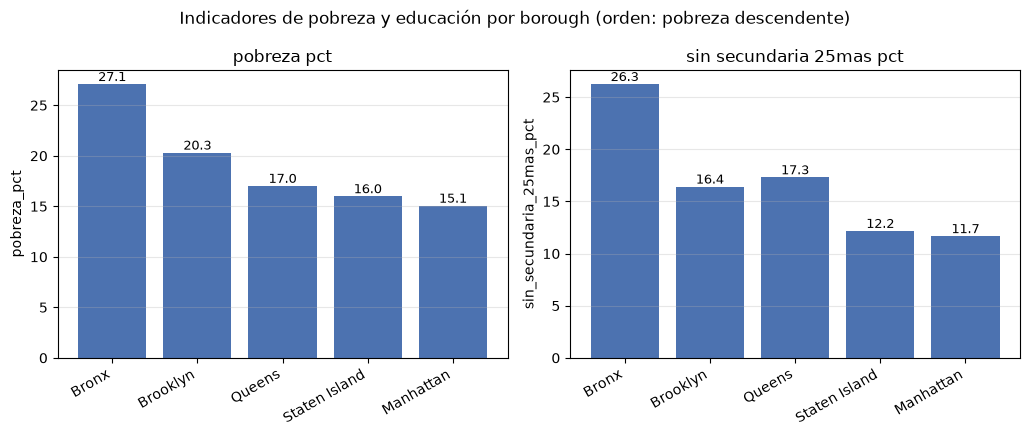

In [22]:
NOMBRES_ETIQUETA = {
    "tasa_arrestos_100k": "Arrestos totales",
    "tasa_felony_100k": "Felony",
    "tasa_misdemeanor_100k": "Misdemeanor",
    "tasa_violentos_100k": "Violentos",
    "tasa_drogas_100k": "Drogas",
    "tasa_armas_100k": "Armas",
    "tasa_propiedad_100k": "Propiedad",
    "pct_felony": "% felony",
    "arrestos": "Arrestos totales",
    "arrestos_felony": "Felony",
    "arrestos_misdemeanor": "Misdemeanor",
    "arrestos_violentos": "Violentos",
    "arrestos_drogas": "Drogas",
    "arrestos_armas": "Armas",
    "arrestos_propiedad": "Propiedad",
}
def etiqueta(c):
    return NOMBRES_ETIQUETA.get(c, c.replace("_", " "))
 
indice = tabla.set_index("borough")
orden_pobreza = indice.sort_values(COL_POBREZA, ascending=False).index.tolist()
 
fig, ejes = plt.subplots(1, len(SOCIO), figsize=(5.2 * len(SOCIO), 4.4), squeeze=False)
for eje, col in zip(ejes[0], SOCIO):
    serie = indice.loc[orden_pobreza, col]
    barras = eje.bar(serie.index, serie.values, color="#4C72B0")
    eje.set_title(etiqueta(col))
    eje.set_ylabel(col)
    plt.setp(eje.get_xticklabels(), rotation=30, ha="right")
    for b, v in zip(barras, serie.values):
        eje.text(b.get_x() + b.get_width() / 2, v, f"{v:.1f}", ha="center", va="bottom", fontsize=9)
    eje.grid(axis="y", alpha=0.3)
fig.suptitle("Indicadores de pobreza y educación por borough (orden: pobreza descendente)")
plt.tight_layout()
fig.savefig(RESULTADOS_P78 / "P7_01_perfil_socioeconomico.png", dpi=150)
plt.show()

**Análisis:** La distribución territorial de los indicadores de pobreza y educación evidencia importantes desigualdades entre los cinco *boroughs* de Nueva York. El Bronx presenta las condiciones más desfavorables en ambas dimensiones, con un 27,1 % de población en situación de pobreza y un 26,3 % de personas mayores de 25 años sin educación secundaria. En contraste, Manhattan registra los porcentajes más bajos de pobreza (15,1 %) y rezago educativo (11,7 %), seguido de cerca por Staten Island.

Estos resultados sugieren una correspondencia territorial entre las condiciones económicas y educativas: los distritos con mayores niveles de pobreza también tienden a presentar mayores proporciones de población con bajos niveles educativos. No obstante, esta correspondencia no es uniforme. Queens, por ejemplo, presenta un porcentaje de población sin educación secundaria superior al de Brooklyn, aunque su nivel de pobreza es menor. Esto indica que las desigualdades socioeconómicas y educativas responden a dinámicas territoriales diferenciadas y que deben analizarse de manera conjunta, sin asumir una relación causal directa entre ellas.

In [23]:
print("Ranking por indicador (1 = valor más alto):")
display(indice[SOCIO].rank(ascending=False, method="min").astype(int))

Ranking por indicador (1 = valor más alto):


,pobreza_pct,sin_secundaria_25mas_pct
borough,,
Bronx,1,1
Brooklyn,2,3
Manhattan,5,5
Queens,3,2
Staten Island,4,4


**Análisis:** El ranking por indicador permite identificar una correspondencia importante en la distribución territorial de las desigualdades socioeconómicas y educativas entre los cinco boroughs de Nueva York. El Bronx ocupa la primera posición en ambos indicadores, mientras que Manhattan se ubica en la quinta, lo que confirma la persistencia de diferencias territoriales entre los distritos con condiciones más y menos desfavorables. Por su parte, Staten Island mantiene una posición intermedia consistente (cuarto lugar en ambos indicadores).

Las principales diferencias se presentan entre Brooklyn y Queens: mientras Brooklyn ocupa una posición más desfavorable en pobreza (segundo lugar), Queens presenta una posición más desfavorable en rezago educativo (segundo lugar). En conjunto, estos resultados sugieren que la pobreza y el nivel educativo presentan patrones territoriales similares, aunque no idénticos. Por tanto, resulta pertinente considerar ambas dimensiones conjuntamente para caracterizar las condiciones socioeconómicas de cada distrito, evitando asumir que un único indicador representa integralmente las desigualdades territoriales.

## 5.2 Matriz de correlaciones
 
Para cada par (indicador socioeconómico, indicador de seguridad) se calculan:
 
- **Pearson** (relación lineal) y **Spearman** (relación monótona, más robusta a valores extremos).
- **p-valor por permutación exacta**: se enumeran las 120 formas de reordenar los cinco valores de seguridad y se mide qué fracción produce una correlación tan fuerte o más que la observada. Con n = 5, el menor p-valor posible es 2/120 ≈ 0,017.
- **Sensibilidad *leave-one-out***: se recalcula la correlación excluyendo cada distrito (n = 4) para ver si el resultado depende de uno solo.

In [24]:
def fuerza(r):
    a = abs(r)
    if np.isnan(a): return "no calculable"
    return "muy débil" if a < 0.2 else "débil" if a < 0.4 else "moderada" if a < 0.6 else "fuerte" if a < 0.8 else "muy fuerte"
 
def rangos(x):
    return pd.Series(np.asarray(x, dtype=float)).rank().to_numpy()
 
def corr(a, b):
    a = np.asarray(a, dtype=float); b = np.asarray(b, dtype=float)
    if a.std() == 0 or b.std() == 0:
        return np.nan
    return float(np.corrcoef(a, b)[0, 1])
 
def corr_spearman(a, b):
    return corr(rangos(a), rangos(b))
 
def p_permutacion(x, y, metodo="spearman", max_perm=20000, semilla=7):
    """p-valor bilateral por permutación. Exacto si n <= 8; si no, Monte Carlo."""
    x = np.asarray(x, dtype=float); y = np.asarray(y, dtype=float)
    if metodo == "spearman":
        x, y = rangos(x), rangos(y)
    obs = corr(x, y)
    if np.isnan(obs):
        return np.nan
    n = len(y)
    if n <= 8:
        perms = permutations(range(n))
    else:
        rng = np.random.default_rng(semilla)
        perms = (rng.permutation(n) for _ in range(max_perm))
    cuenta = total = 0
    for perm in perms:
        c = corr(x, y[list(perm)])
        total += 1
        if abs(c) >= abs(obs) - 1e-12:
            cuenta += 1
    return cuenta / total
 
def loo(x, y, nombres, metodo):
    f = corr_spearman if metodo == "spearman" else corr
    salida = {}
    for i, nombre in enumerate(nombres):
        mascara = np.arange(len(nombres)) != i
        salida[nombre] = f(np.asarray(x)[mascara], np.asarray(y)[mascara])
    return salida

In [25]:
boroughs = tabla["borough"].tolist()
filas_corr, filas_loo = [], []
for s in SOCIO:
    for g in SEG_P7:
        x, y = tabla[s].to_numpy(float), tabla[g].to_numpy(float)
        pear, spear = corr(x, y), corr_spearman(x, y)
        loo_sp = loo(x, y, boroughs, "spearman")
        valores_loo = [v for v in loo_sp.values() if not np.isnan(v)]
        filas_corr.append({
            "indicador_socio": s, "indicador_seguridad": g,
            "pearson": pear, "spearman": spear,
            "p_perm_pearson": p_permutacion(x, y, "pearson"),
            "p_perm_spearman": p_permutacion(x, y, "spearman"),
            "spearman_loo_min": min(valores_loo) if valores_loo else np.nan,
            "spearman_loo_max": max(valores_loo) if valores_loo else np.nan,
            "signo_estable": bool(valores_loo) and (all(v > 0 for v in valores_loo) or all(v < 0 for v in valores_loo)),
            "fuerza_spearman": fuerza(spear),
        })
        for dist, v in loo_sp.items():
            filas_loo.append({"indicador_socio": s, "indicador_seguridad": g, "distrito_excluido": dist,
                              "spearman_sin_distrito": v, "spearman_completo": spear})
 
corr_df = pd.DataFrame(filas_corr)
loo_df = pd.DataFrame(filas_loo)
corr_df.to_csv(RESULTADOS_P78 / "P7_correlaciones.csv", index=False)
loo_df.to_csv(RESULTADOS_P78 / "P7_leave_one_out.csv", index=False)
 
print(f"Pares evaluados: {len(corr_df)}")
display(corr_df.round(3))

Pares evaluados: 16


,indicador_socio,indicador_seguridad,pearson,spearman,p_perm_pearson,p_perm_spearman,spearman_loo_min,spearman_loo_max,signo_estable,fuerza_spearman
0,pobreza_pct,tasa_arrestos_100k,0.441,0.4,0.492,0.517,-0.2,1.0,False,débil
1,pobreza_pct,tasa_felony_100k,0.426,0.0,0.467,1.000,-0.2,1.0,False,muy débil
2,pobreza_pct,tasa_misdemeanor_100k,0.449,0.3,0.517,0.683,-0.4,0.8,False,débil
3,pobreza_pct,tasa_violentos_100k,0.874,0.4,0.100,0.517,-0.2,1.0,False,débil
4,pobreza_pct,tasa_drogas_100k,0.682,0.3,0.258,0.683,-0.4,0.8,False,débil
5,pobreza_pct,tasa_armas_100k,0.847,0.7,0.075,0.233,0.4,1.0,True,fuerte
6,pobreza_pct,tasa_propiedad_100k,-0.153,-0.1,0.742,0.950,-0.4,0.8,False,muy débil
7,pobreza_pct,pct_felony,-0.221,0.0,0.733,1.000,-0.2,1.0,False,muy débil
8,sin_secundaria_25mas_pct,tasa_arrestos_100k,0.370,0.3,0.625,0.683,-0.4,0.8,False,débil
9,sin_secundaria_25mas_pct,tasa_felony_100k,0.326,-0.1,0.658,0.950,-0.4,0.8,False,muy débil


**Análisis:** Las correlaciones entre los indicadores socioeconómicos y de seguridad muestran una tendencia descriptiva positiva entre los niveles de pobreza y rezago educativo y algunas tasas de arrestos por cada 100.000 habitantes. Sin embargo, la magnitud y consistencia de estas asociaciones varían considerablemente según el indicador evaluado.

El resultado más destacado corresponde a la relación entre pobreza y arrestos relacionados con armas, que presenta una correlación de Spearman de 0,7, clasificada como fuerte, y mantiene su signo positivo al excluir individualmente cualquiera de los cinco distritos. También se observan correlaciones positivas elevadas entre pobreza y arrestos por delitos violentos (Pearson = 0,874), así como entre rezago educativo y arrestos relacionados con armas (Pearson = 0,752). No obstante, estas últimas asociaciones presentan menor estabilidad al evaluar las variaciones en la composición de los distritos.

Es importante señalar que ninguno de los 16 pares evaluados presenta valores de significancia por permutación inferiores a 0,05. Además, la mayoría de las correlaciones de Spearman son débiles o muy débiles y muestran sensibilidad a la exclusión de distritos individuales. Esto limita la posibilidad de identificar asociaciones territoriales consistentes entre las condiciones socioeconómicas y los indicadores de seguridad.

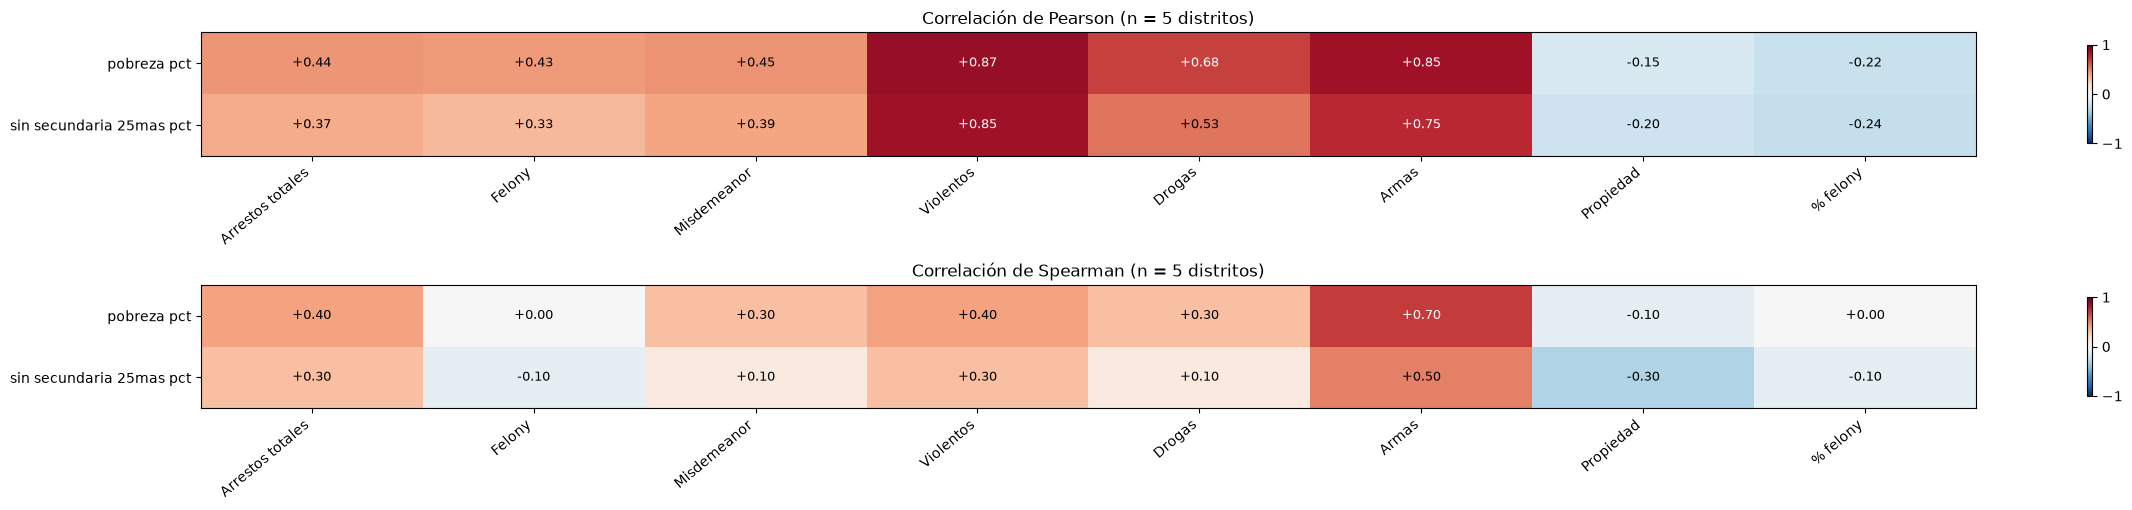

In [27]:
fig, ejes = plt.subplots(2, 1, figsize=(2 * (1.15 * len(SEG_P7) + 3), 1.0 * len(SOCIO) + 3.2))
for eje, metrica, titulo in zip(ejes, ["pearson", "spearman"], ["Pearson", "Spearman"]):
    mat = corr_df.pivot(index="indicador_socio", columns="indicador_seguridad", values=metrica).loc[SOCIO, SEG_P7]
    im = eje.imshow(mat.values, cmap="RdBu_r", vmin=-1, vmax=1, aspect="auto")
    eje.set_xticks(range(len(SEG_P7)))
    eje.set_xticklabels([etiqueta(c) for c in SEG_P7], rotation=40, ha="right")
    eje.set_yticks(range(len(SOCIO)))
    eje.set_yticklabels([etiqueta(c) for c in SOCIO])
    for i in range(mat.shape[0]):
        for j in range(mat.shape[1]):
            v = mat.values[i, j]
            if not np.isnan(v):
                eje.text(j, i, f"{v:+.2f}", ha="center", va="center", color="white" if abs(v) > 0.6 else "black", fontsize=9)
    eje.set_title(f"Correlación de {titulo} (n = 5 distritos)")
    fig.colorbar(im, ax=eje, shrink=0.8)
plt.tight_layout()
fig.savefig(RESULTADOS_P78 / "P7_02_heatmap_correlaciones.png", dpi=150)
plt.show()

**Análisis:** Desde los mapas de calor podemos observar que, en términos generales, las correlaciones de Pearson muestran una tendencia positiva entre los niveles de pobreza y rezago educativo y las tasas de arrestos, especialmente en las categorías de delitos violentos (0,87 y 0,85) y relacionados con armas (0,85 y 0,75). Sin embargo, estas asociaciones disminuyen considerablemente al utilizar la correlación de Spearman, lo que sugiere que las magnitudes observadas mediante Pearson no necesariamente representan una correspondencia consistente en el orden relativo de los distritos.

La principal excepción corresponde a los arrestos relacionados con armas, que mantienen correlaciones relativamente elevadas tanto con la pobreza (Spearman = 0,70) como con el rezago educativo (Spearman = 0,50). Este resultado coincide con el análisis de estabilidad realizado previamente y señala una posible correspondencia territorial entre las condiciones socioeconómicas desfavorables y esta categoría de arrestos. Por el contrario, las asociaciones con los arrestos por delitos violentos, drogas y delitos contra la propiedad presentan menor consistencia entre ambos métodos.

En conjunto, los resultados sugieren que las relaciones entre desigualdad socioeconómica y seguridad varían según la categoría de arrestos considerada y no permiten establecer un patrón generalizado. Sin embargo, el reducido número de observaciones (cinco distritos) constituye una limitación central del análisis y hace necesario interpretar estos resultados como exploratorios. Por tanto, se reconocen posibles correspondencias territoriales, pero no se pueden establecer relaciones causales entre las condiciones socioeconómicas y los niveles de criminalidad o arrestos.

## 5.3 Diagramas de dispersión
 
Con cinco puntos, el diagrama dice más que el coeficiente: permite ver **qué distrito sostiene o rompe** la relación. La línea es un ajuste lineal puramente descriptivo.

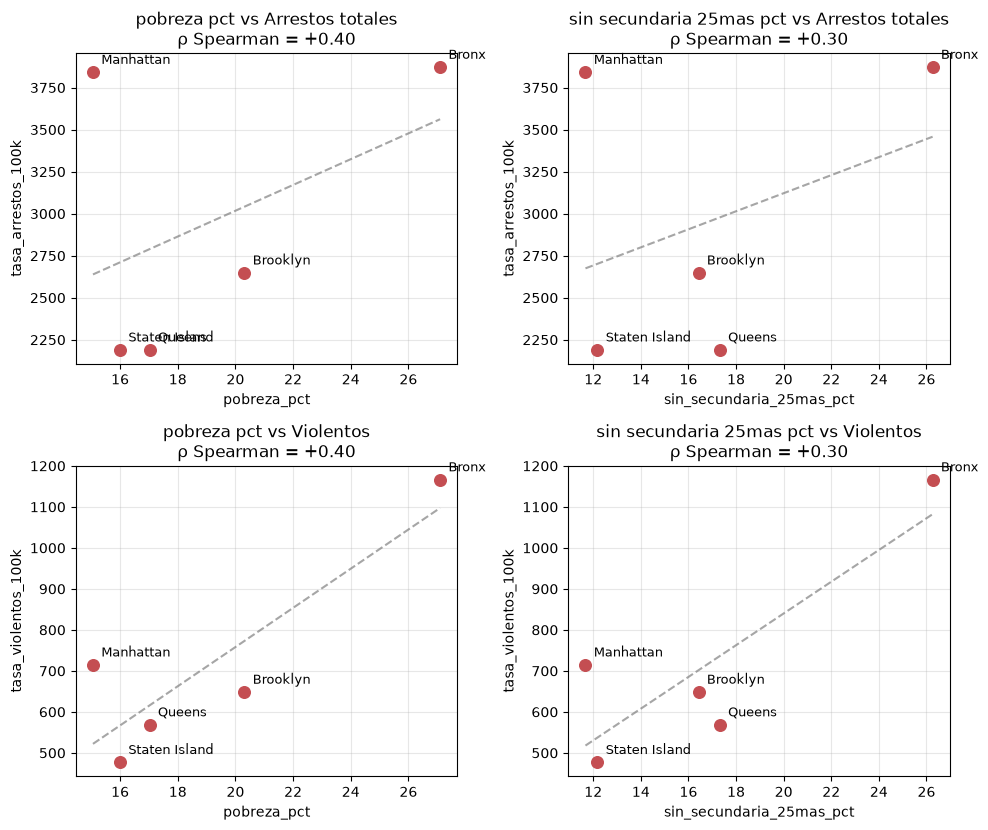

In [28]:
PARES_SEG = [g for g in ["tasa_arrestos_100k", "tasa_violentos_100k"] if g in tabla.columns]
fig, ejes = plt.subplots(len(PARES_SEG), len(SOCIO), figsize=(5.0 * len(SOCIO), 4.2 * len(PARES_SEG)), squeeze=False)
for i, g in enumerate(PARES_SEG):
    for j, s in enumerate(SOCIO):
        eje = ejes[i][j]
        x, y = tabla[s].to_numpy(float), tabla[g].to_numpy(float)
        eje.scatter(x, y, s=70, color="#C44E52", zorder=3)
        for nombre, xv, yv in zip(tabla["borough"], x, y):
            eje.annotate(nombre, (xv, yv), textcoords="offset points", xytext=(6, 6), fontsize=9)
        if x.std() > 0:
            m, b = np.polyfit(x, y, 1)
            xs = np.linspace(x.min(), x.max(), 50)
            eje.plot(xs, m * xs + b, color="gray", linestyle="--", alpha=0.7)
        rho = corr_spearman(x, y)
        eje.set_title(f"{etiqueta(s)} vs {etiqueta(g)}\nρ Spearman = {rho:+.2f}")
        eje.set_xlabel(s)
        eje.set_ylabel(g)
        eje.grid(alpha=0.3)
plt.tight_layout()
fig.savefig(RESULTADOS_P78 / "P7_03_dispersion.png", dpi=150)
plt.show()

**Análisis:** En los diagramas de dispersión, el Bronx (pobreza ≈ 27 %, sin secundaria ≈ 26 %) y Manhattan (pobreza ≈ 15 %, sin secundaria ≈ 12 %) presentan las tasas de arrestos totales más altas (≈ 3.870 y ≈ 3.840 por 100.000 habitantes), a pesar de ser los extremos opuestos en condiciones socioeconómicas. Brooklyn se ubica en ≈ 2.650 y Queens y Staten Island en ≈ 2.190. Los dos indicadores muestran la dirección esperada (a mayor pobreza o mayor proporción de población sin secundaria, mayor tasa de arrestos), pero con ρ = +0,40 y +0,30 la asociación es débil, y Manhattan es su principal causa: es un distrito de baja pobreza cuya tasa es casi igual a la del Bronx, lo que aplana la relación.

Con arrestos violentos la lectura es más limpia: los puntos siguen mejor la línea de ajuste y el Bronx se distancia claramente (≈ 1.166 por 100.000 frente a 477–715 en los demás distritos). El ρ de Spearman se mantiene en +0,40 y +0,30, pero el Pearson es alto (0,87 y 0,85). La diferencia se explica porque Spearman solo considera el orden de los distritos (y Manhattan, el de menor pobreza, queda segundo en violentos, lo que desordena el ranking), mientras que Pearson recoge la magnitud, dominada por el Bronx. Por ello conviene reportar ambos coeficientes y explicar su diferencia.

Manhattan es además un caso particular: su tasa de arrestos totales es alta, pero en violentos queda a distancia del Bronx (≈ 715 frente a ≈ 1.166). Esto sugiere que su tasa total se explica en parte por otros tipos de arresto (en particular contra la propiedad, donde registra la tasa más alta de la ciudad, ≈ 1.348 por 100.000) y, posiblemente, por la población flotante que el denominador residente no recoge. Se trata de una hipótesis, no de un resultado que estos datos puedan probar.

Finalmente, Queens y Staten Island son prácticamente un empate en arrestos totales (diferencia de 0,02 %), por lo que su orden relativo no es defendible.

## 5.4 Robustez: sensibilidad *leave-one-out*
 
Para los pares principales (pobreza y educación contra la tasa total y la tasa de violentos) se muestra cuánto cambia ρ al excluir cada distrito y cuál es el **distrito más influyente**.

In [30]:
principales = loo_df[loo_df["indicador_seguridad"].isin(PARES_SEG)].copy()
principales["cambio"] = principales["spearman_sin_distrito"] - principales["spearman_completo"]
 
resumen_loo = []
for (s, g), grupo in principales.groupby(["indicador_socio", "indicador_seguridad"], sort=False):
    fila_max = grupo.loc[grupo["cambio"].abs().idxmax()]
    completo = grupo["spearman_completo"].iloc[0]
    resumen_loo.append({
        "indicador_socio": s, "indicador_seguridad": g,
        "rho_completo": completo,
        "rho_min_loo": grupo["spearman_sin_distrito"].min(),
        "rho_max_loo": grupo["spearman_sin_distrito"].max(),
        "distrito_mas_influyente": fila_max["distrito_excluido"],
        "cambio_max": fila_max["cambio"],
        "cambia_signo": bool((grupo["spearman_sin_distrito"] * completo < 0).any()),
    })
resumen_loo = pd.DataFrame(resumen_loo)
resumen_loo.to_csv(RESULTADOS_P78 / "P7_resumen_leave_one_out.csv", index=False)
display(resumen_loo.round(3))

,indicador_socio,indicador_seguridad,rho_completo,rho_min_loo,rho_max_loo,distrito_mas_influyente,cambio_max,cambia_signo
0,pobreza_pct,tasa_arrestos_100k,0.4,-0.2,1.0,Manhattan,0.6,True
1,pobreza_pct,tasa_violentos_100k,0.4,-0.2,1.0,Manhattan,0.6,True
2,sin_secundaria_25mas_pct,tasa_arrestos_100k,0.3,-0.4,0.8,Bronx,-0.7,True
3,sin_secundaria_25mas_pct,tasa_violentos_100k,0.3,-0.4,0.8,Bronx,-0.7,True


**Análisis:** La sensibilidad mediante el procedimiento leave-one-out evidencia que las asociaciones entre los indicadores socioeconómicos y de seguridad presentan una considerable dependencia de determinadas observaciones. En particular, Manhattan resulta ser el distrito más influyente en las correlaciones que involucran pobreza, mientras que el Bronx presenta mayor influencia en aquellas relacionadas con la proporción de población sin educación secundaria.

Esta influencia se refleja en variaciones importantes de los coeficientes de Spearman al excluir dichos distritos: las correlaciones asociadas con pobreza oscilan entre -0.2 y 1.0, mientras que aquellas relacionadas con el nivel educativo varían entre -0.4 y 0.8. Además, en todos los casos se identifica la posibilidad de un cambio de signo respecto a la correlación completa.

En consecuencia, aunque las correlaciones originales sugieren asociaciones positivas entre las condiciones socioeconómicas y los indicadores de seguridad, estas relaciones deben interpretarse con cautela, dado que su dirección y magnitud no se mantienen estables ante la exclusión individual de determinados distritos.

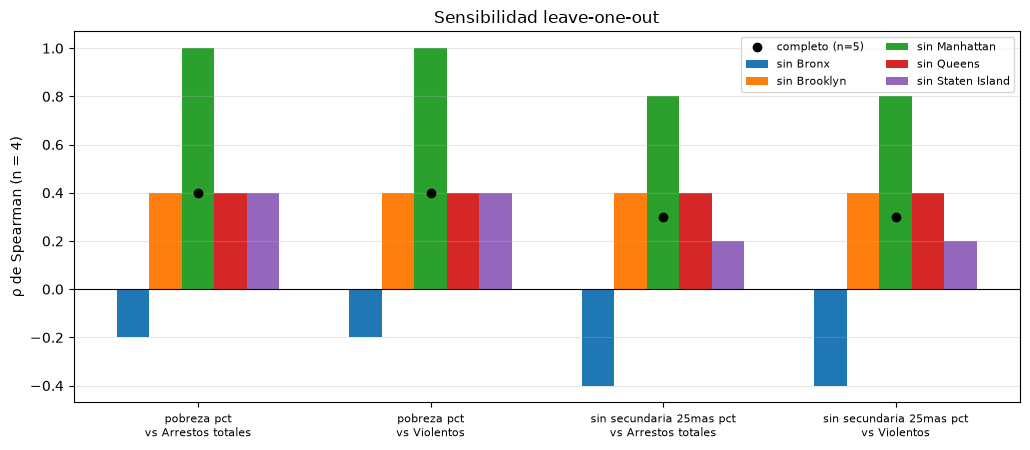

In [31]:
# Gráfica: ρ al excluir cada distrito
pares = list(resumen_loo[["indicador_socio", "indicador_seguridad"]].itertuples(index=False, name=None))
fig, eje = plt.subplots(figsize=(1.6 * len(pares) + 4, 4.6))
ancho = 0.14
for k, dist in enumerate(boroughs):
    vals = [principales[(principales["indicador_socio"] == s) & (principales["indicador_seguridad"] == g)
                        & (principales["distrito_excluido"] == dist)]["spearman_sin_distrito"].iloc[0] for s, g in pares]
    eje.bar(np.arange(len(pares)) + (k - 2) * ancho, vals, width=ancho, label=f"sin {dist}")
eje.scatter(np.arange(len(pares)), resumen_loo["rho_completo"], color="black", zorder=5, label="completo (n=5)")
eje.axhline(0, color="black", linewidth=0.8)
eje.set_xticks(np.arange(len(pares)))
eje.set_xticklabels([f"{etiqueta(s)}\nvs {etiqueta(g)}" for s, g in pares], fontsize=8)
eje.set_ylabel("ρ de Spearman (n = 4)")
eje.set_title("Sensibilidad leave-one-out")
eje.legend(fontsize=8, ncol=2)
eje.grid(axis="y", alpha=0.3)
plt.tight_layout()
fig.savefig(RESULTADOS_P78 / "P7_04_leave_one_out.png", dpi=150)
plt.show()

**Análisis:** La gráfica muestra, para los cuatro pares principales, el ρ de Spearman con los cinco distritos (punto negro) y al excluir cada uno (barras). Se observan tres resultados.

Primero, excluir Brooklyn, Queens o Staten Island casi no altera la relación: ρ permanece en 0,4 en las dos relaciones de pobreza y entre 0,2 y 0,4 en las de rezago educativo. Esos tres distritos no determinan el resultado.

Segundo, las observaciones que sí lo mueven son el Bronx y Manhattan, y lo hacen en sentidos opuestos. Al excluir Manhattan, ρ sube a 1,0 (pobreza) y 0,8 (sin secundaria), porque Manhattan es el único distrito de baja pobreza con una tasa de arrestos alta. Al excluir el Bronx, ρ cae a −0,2 y −0,4, porque el Bronx reúne a la vez la mayor pobreza, el mayor rezago educativo y la tasa de arrestos más alta. En los cuatro pares, el cambio de signo ocurre únicamente cuando se excluye el Bronx.

Tercero, el patrón es idéntico para arrestos totales y para arrestos violentos, por lo que no depende de cómo se defina el indicador de seguridad. En síntesis, la tendencia positiva descansa en un único distrito extremo (el Bronx) y su debilidad se debe a otro (Manhattan). Además, con n = 4 tras cada exclusión, los coeficientes toman solo valores en saltos de 0,2, de modo que no hay base para generalizar.

In [57]:
principal_g = "tasa_arrestos_100k"
lineas = []
for s in SOCIO:
    fila = corr_df[(corr_df["indicador_socio"] == s) & (corr_df["indicador_seguridad"] == principal_g)].iloc[0]
    lineas.append(
        f"- **{etiqueta(s)}** vs tasa de arrestos: ρ = {fila['spearman']:+.2f} ({fila['fuerza_spearman']}), "
        f"Pearson = {fila['pearson']:+.2f}, p (permutación) = {fila['p_perm_spearman']:.3f}; "
        f"al excluir un distrito ρ varía entre {fila['spearman_loo_min']:+.2f} y {fila['spearman_loo_max']:+.2f} "
        f"({'signo estable' if fila['signo_estable'] else 'el signo CAMBIA'})."
    )
 
m_pruebas = len(corr_df)
n_sig = int((corr_df["p_perm_spearman"] <= 0.05).sum())
mas_fuerte = corr_df.loc[corr_df["spearman"].abs().idxmax()]
mas_debil = corr_df.loc[corr_df["spearman"].abs().idxmin()]
estables = int(corr_df["signo_estable"].sum())
 
texto_p7 = f"""
### Respuesta a la pregunta 7
 
Con los cinco boroughs de Nueva York en 2018, la relación entre los indicadores territoriales de pobreza/educación y la seguridad (medida con arrestos por 100.000 habitantes) es la siguiente:
 
{chr(10).join(lineas)}
 
- De los {m_pruebas} pares evaluados, {n_sig} tienen p ≤ 0,05 por permutación exacta (por azar se esperarían ≈ {0.05 * m_pruebas:.1f}), y {estables} {'conserva' if estables == 1 else 'conservan'} el signo al excluir cualquier distrito.
- La asociación más fuerte es **{etiqueta(mas_fuerte['indicador_socio'])} vs {etiqueta(mas_fuerte['indicador_seguridad'])}** (ρ = {mas_fuerte['spearman']:+.2f}); la más débil es **{etiqueta(mas_debil['indicador_socio'])} vs {etiqueta(mas_debil['indicador_seguridad'])}** (ρ = {mas_debil['spearman']:+.2f}).

"""
display(Markdown(texto_p7))


### Respuesta a la pregunta 8
 
Al normalizar los arrestos por población (tasa por 100.000 habitantes), la lectura territorial cambia de forma importante:
 
- **Ranking por conteo:** Brooklyn > Manhattan > Bronx > Queens > Staten Island. **Ranking por tasa:** Bronx > Manhattan > Brooklyn > Queens > Staten Island.
- El distrito con más arrestos en términos absolutos es **Brooklyn**; el de mayor tasa es **Bronx**.
- Suben al normalizar: Bronx (de 3.º a 1.º). Bajan: Brooklyn (de 1.º a 3.º).
- El índice de concentración (% de arrestos / % de población) es máximo en **Bronx** (1.32) y mínimo en **Staten Island** (0.75).
- El conteo total sigue de cerca el tamaño poblacional (ρ de Spearman población–conteo = +0.70), mientras que la tasa lo hace mucho menos (ρ = +0.10): la normalización elimina el efecto de escala.
- El líder del ranking cambia al normalizar en 6 de 7 indicadores de seguridad analizados.
- En las correlaciones con pobreza y educación, el signo cambia al pasar de conteos a tasas en 1 de 6 comparaciones evaluadas.
- **Robustez:** la menor diferencia entre tasas contiguas es 0.02 % (Queens vs Staten Island); el orden entre esos dos distritos no es defendible. 9 de 20 escenarios de ±10 % y ±20 % en la población de un distrito alteran el ranking.



## **Conclusión de la pregunta 7**

**Respuesta.** Los indicadores territoriales de pobreza y educación se relacionan con los indicadores de seguridad de forma **positiva pero débil, inestable y no concluyente**. En los cinco boroughs de Nueva York (2018), los distritos con mayor pobreza y mayor proporción de población de 25 años o más sin secundaria tienden a registrar más arrestos por 100.000 habitantes, pero los datos no permiten afirmar una asociación territorial consistente.

**Evidencia que sustenta la respuesta**

1. **Perfil socioeconómico.** El Bronx es el distrito más desfavorable en ambas dimensiones (pobreza 27,1 %; sin secundaria 26,3 %) y Manhattan el menos desfavorable (15,1 % y 11,7 %). Los indicadores coinciden en los extremos, pero no en los intermedios: Brooklyn es segundo en pobreza y Queens en rezago educativo.
2. **Arrestos totales.** ρ de Spearman = +0,40 (pobreza) y +0,30 (sin secundaria); Pearson = 0,44 y 0,37; p por permutación = 0,517 y 0,683. La dirección es la esperada, pero la magnitud es débil.
3. **Según el tipo de arresto.** Armas es la relación más fuerte (pobreza ρ = 0,70; sin secundaria ρ = 0,50) y la única entre las 16 que conserva el signo al excluir cualquier distrito, pero tampoco es significativa (p = 0,233 y 0,450). En arrestos violentos el Pearson es alto (0,87 y 0,85) y el Spearman bajo (0,4 y 0,3): la magnitud depende del Bronx (≈ 1.166 por 100.000 frente a 477–715 en los demás). En felony y en delitos contra la propiedad la relación es nula o ligeramente negativa (por ejemplo, pobreza–felony ρ = 0,0 y sin secundaria–propiedad ρ = −0,3), porque Manhattan, el distrito menos pobre, tiene las tasas más altas en ambas categorías (≈ 1.248 y ≈ 1.348).
4. **Robustez.** Ninguno de los 16 pares es significativo (el menor p es 0,233; por azar se esperarían ≈ 0,8 pares con p ≤ 0,05). Excluir el Bronx invierte el signo en los cuatro pares principales (ρ entre −0,2 y −0,4) y excluir Manhattan lo eleva a 1,0 y 0,8: la tendencia positiva descansa en el Bronx y su debilidad proviene de Manhattan.
5. **Contraste de hipótesis.** H1 y H2 quedan *matizadas* (dirección esperada, magnitud débil), H3 sin diferencia clara entre delitos graves y total, y H4 y H5 *apoyadas* (el signo cambia al excluir un distrito y Manhattan es influyente).

**Lectura final.** El Bronx concentra a la vez las mayores carencias y la tasa de arrestos más alta, pero Manhattan muestra que la tasa de arrestos no se explica solo por pobreza o educación: otros factores, como la actividad comercial, la población flotante o la intensidad de la actividad policial, pueden pesar más en algunos territorios. Con cinco territorios, los resultados son **exploratorios**: no permiten establecer causalidad ni inferir relaciones entre personas (falacia ecológica), y los arrestos no equivalen a delitos. Para contrastar estas relaciones con potencia real se requiere una unidad territorial más fina (precinto o PUMA).

# 6. Pregunta 8 — Normalización por población
 
> ¿Cómo cambian los indicadores territoriales de seguridad cuando se normalizan por población?
 
La normalización convierte el **conteo** de arrestos en una **tasa por 100.000 habitantes**: `tasa = arrestos / población × 100.000`. Un conteo responde "¿dónde hay más arrestos?"; una tasa responde "¿dónde es más frecuente un arresto por habitante?". Son preguntas distintas y pueden tener respuestas distintas.
 
## 6.1 Conteos vs. tasas: cambio de posiciones

In [58]:
comp = tabla.set_index("borough")[["poblacion", "arrestos", "tasa_arrestos_100k", "pct_arrestos", "pct_poblacion"]].copy()
comp["indice_concentracion"] = comp["pct_arrestos"] / comp["pct_poblacion"]
comp["rank_conteo"] = comp["arrestos"].rank(ascending=False, method="min").astype(int)
comp["rank_tasa"] = comp["tasa_arrestos_100k"].rank(ascending=False, method="min").astype(int)
comp["cambio_posiciones"] = comp["rank_conteo"] - comp["rank_tasa"]   # positivo: sube en el ranking al normalizar
comp = comp.sort_values("rank_tasa")
comp.round(2).to_csv(RESULTADOS_P78 / "P8_conteos_vs_tasas.csv")
display(comp.round(2))

,poblacion,arrestos,tasa_arrestos_100k,pct_arrestos,pct_poblacion,indice_concentracion,rank_conteo,rank_tasa,cambio_posiciones
borough,,,,,,,,,
Bronx,1432000,55446,3871.93,22.47,17.05,1.32,3,1,2
Manhattan,1629000,62582,3841.74,25.36,19.40,1.31,2,2,0
Brooklyn,2583000,68405,2648.28,27.72,30.75,0.90,1,3,-2
Queens,2279000,49916,2190.26,20.23,27.13,0.75,4,4,0
Staten Island,476000,10424,2189.92,4.22,5.67,0.75,5,5,0


**Análisis:** La comparación entre los conteos absolutos y las tasas de arrestos por cada 100.000 habitantes evidencia diferencias en la distribución territorial de los registros según la medida utilizada. Mientras Brooklyn ocupa el primer lugar en número absoluto de arrestos, desciende a la tercera posición al considerar su tamaño poblacional. En contraste, el Bronx pasa del tercer al primer lugar, registrando la tasa más elevada (3.871,93), seguido de Manhattan (3.841,74).

Estas diferencias también se reflejan en los índices de concentración. El Bronx y Manhattan presentan valores de 1,32 y 1,31, respectivamente, lo que indica que su participación en los arrestos supera su participación en la población. Por el contrario, Brooklyn, Queens y Staten Island registran índices inferiores a 1, evidenciando una participación relativa en los arrestos menor a su peso poblacional.

Por tanto, los resultados muestran que los conteos absolutos y las tasas ofrecen perspectivas distintas sobre la distribución territorial de los arrestos. Mientras los primeros permiten identificar dónde se concentra el mayor volumen de registros, las segundas permiten dimensionar su magnitud en relación con la población residente. Por tanto, utilizar exclusivamente conteos absolutos podría conducir a una interpretación incompleta de las diferencias territoriales, especialmente en distritos con tamaños poblacionales considerablemente distintos.

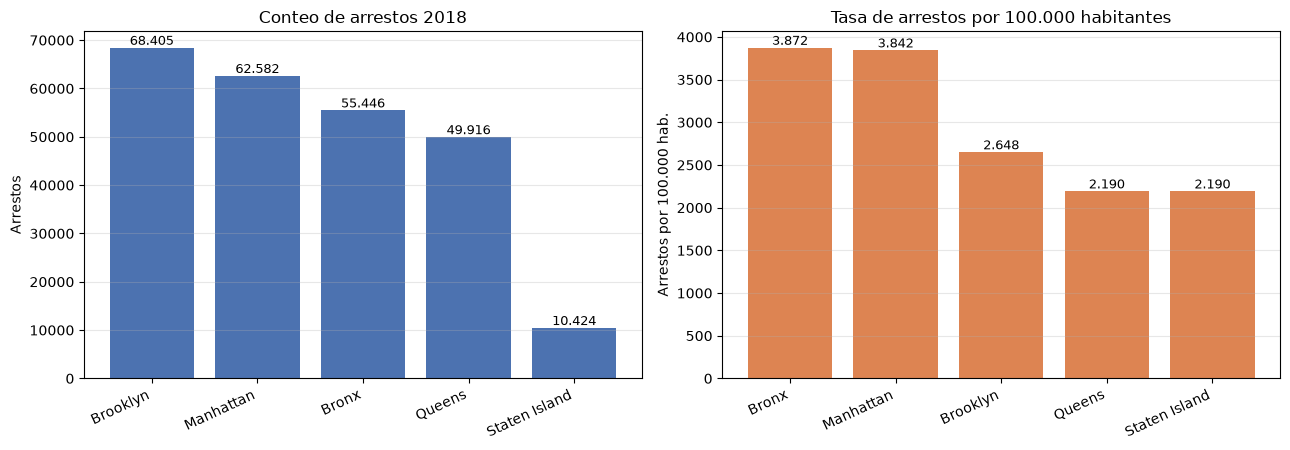

In [59]:
por_conteo = comp.sort_values("arrestos", ascending=False)
por_tasa = comp.sort_values("tasa_arrestos_100k", ascending=False)
fig, ejes = plt.subplots(1, 2, figsize=(13, 4.6))
b1 = ejes[0].bar(por_conteo.index, por_conteo["arrestos"], color="#4C72B0")
ejes[0].set_title("Conteo de arrestos 2018")
ejes[0].set_ylabel("Arrestos")
for b, v in zip(b1, por_conteo["arrestos"]):
    ejes[0].text(b.get_x() + b.get_width() / 2, v, f"{v:,.0f}".replace(",", "."), ha="center", va="bottom", fontsize=9)
b2 = ejes[1].bar(por_tasa.index, por_tasa["tasa_arrestos_100k"], color="#DD8452")
ejes[1].set_title("Tasa de arrestos por 100.000 habitantes")
ejes[1].set_ylabel("Arrestos por 100.000 hab.")
for b, v in zip(b2, por_tasa["tasa_arrestos_100k"]):
    ejes[1].text(b.get_x() + b.get_width() / 2, v, f"{v:,.0f}".replace(",", "."), ha="center", va="bottom", fontsize=9)
for eje in ejes:
    plt.setp(eje.get_xticklabels(), rotation=25, ha="right")
    eje.grid(axis="y", alpha=0.3)
plt.tight_layout()
fig.savefig(RESULTADOS_P78 / "P8_01_conteo_vs_tasa.png", dpi=150)
plt.show()

**Análisis:** Las barras muestran dos ordenamientos distintos de la misma variable. Por conteo, Brooklyn (68.405) encabeza, seguido de Manhattan (62.582), Bronx (55.446), Queens (49.916) y Staten Island (10.424), un orden que coincide en lo esencial con el tamaño poblacional. Por tasa, el panorama se reorganiza en tres niveles: uno alto, con Bronx (3.872) y Manhattan (3.842); uno intermedio, con Brooklyn (2.648); y uno bajo, con Queens y Staten Island (≈ 2.190 ambos).

El cambio de lectura es considerable. Brooklyn registra un 23 % más de arrestos que el Bronx, pero su tasa es un 32 % menor (equivalentemente, la tasa del Bronx es un 46 % mayor que la de Brooklyn). Staten Island tiene solo el 15 % de los arrestos de Brooklyn, pero su tasa equivale al 83 % de la de Brooklyn, lo que indica que su bajo volumen obedece sobre todo a su reducido tamaño y no a una baja frecuencia relativa. Entre el nivel alto y el bajo la diferencia es de aproximadamente 1,8 veces (3.872 frente a 2.190).

Dentro de cada nivel las diferencias son mínimas: Bronx y Manhattan se separan en 0,78 % y Queens y Staten Island en 0,02 %, por lo que las barras de cada par son prácticamente indistinguibles. Esto anticipa el análisis de robustez de la sección 6.5.

## 6.2 Cambio de ranking y participación vs. población

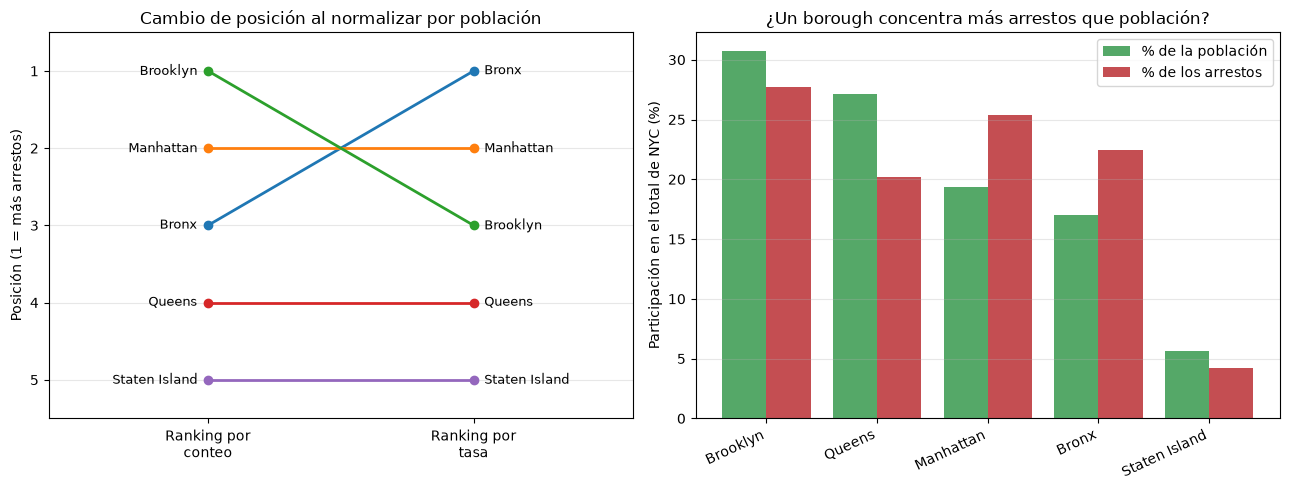

In [61]:
fig, ejes = plt.subplots(1, 2, figsize=(13, 5))
 
# (a) Gráfica de pendiente: ranking por conteo -> ranking por tasa
eje = ejes[0]
for nombre, fila in comp.iterrows():
    eje.plot([0, 1], [fila["rank_conteo"], fila["rank_tasa"]], marker="o", linewidth=2)
    eje.text(-0.04, fila["rank_conteo"], nombre, ha="right", va="center", fontsize=9)
    eje.text(1.04, fila["rank_tasa"], nombre, ha="left", va="center", fontsize=9)
eje.set_xlim(-0.6, 1.6)
eje.set_ylim(5.5, 0.5)
eje.set_xticks([0, 1])
eje.set_xticklabels(["Ranking por\nconteo", "Ranking por\ntasa"])
eje.set_yticks(range(1, 6))
eje.set_ylabel("Posición (1 = más arrestos)")
eje.set_title("Cambio de posición al normalizar por población")
eje.grid(axis="y", alpha=0.3)
 
# (b) Participación en arrestos vs participación en población
eje = ejes[1]
orden = comp.sort_values("pct_poblacion", ascending=False).index
x = np.arange(len(orden))
eje.bar(x - 0.2, comp.loc[orden, "pct_poblacion"], width=0.4, label="% de la población", color="#55A868")
eje.bar(x + 0.2, comp.loc[orden, "pct_arrestos"], width=0.4, label="% de los arrestos", color="#C44E52")
eje.set_xticks(x)
eje.set_xticklabels(orden, rotation=25, ha="right")
eje.set_ylabel("Participación en el total de NYC (%)")
eje.set_title("¿Un borough concentra más arrestos que población?")
eje.legend()
eje.grid(axis="y", alpha=0.3)
plt.tight_layout()
fig.savefig(RESULTADOS_P78 / "P8_02_ranking_y_participacion.png", dpi=150)
plt.show()

**Análisis:** En la gráfica de pendiente solo dos distritos cambian de posición al normalizar: el Bronx sube del tercer al primer lugar y Brooklyn baja del primero al tercero. Manhattan (2.º), Queens (4.º) y Staten Island (5.º) conservan su posición. Que Manhattan no cambie de lugar no significa que la normalización no lo afecte: su peso en los arrestos (25,4 %) supera ampliamente su peso poblacional (19,4 %).

El gráfico de participación confirma el mecanismo. Manhattan (+6,0 puntos porcentuales) y el Bronx (+5,4 pp) concentran más arrestos que población; entre ambos reúnen el 47,8 % de los arrestos con el 36,4 % de la población. Por el contrario, Queens (−6,9 pp), Brooklyn (−3,0 pp) y Staten Island (−1,4 pp) tienen una participación en los arrestos menor que en la población. Queens es el caso más llamativo: es el segundo distrito más poblado (27,1 %) pero registra solo el 20,2 % de los arrestos, lo que explica su cuarta posición pese a su tamaño.

En conjunto, el cambio de ranking no se debe a que varíen los arrestos, sino a que cada distrito pesa de manera distinta en la población: Brooklyn lidera el conteo porque es el más poblado (30,8 %), no porque concentre más arrestos en términos relativos. Es la misma conclusión que arroja el índice de concentración (Bronx 1,32; Manhattan 1,31; Brooklyn 0,90; Queens y Staten Island 0,75).

## 6.3 ¿Cambia el ranking en todos los indicadores de seguridad?
 
Se repite la comparación para cada indicador (total, `felony`, `misdemeanor`, violentos, drogas, armas, propiedad). La notación `a→b` indica la posición por conteo (a) y por tasa (b).

In [62]:
filas = []
ranks_tabla = pd.DataFrame(index=tabla["borough"])
for conteo, tasa in CONTEO_A_TASA.items():
    rc = tabla.set_index("borough")[conteo].rank(ascending=False, method="min").astype(int)
    rt = tabla.set_index("borough")[tasa].rank(ascending=False, method="min").astype(int)
    ranks_tabla[etiqueta(conteo)] = rc.astype(str) + "→" + rt.astype(str)
    filas.append({
        "indicador": etiqueta(conteo),
        "lider_por_conteo": rc.idxmin(),
        "lider_por_tasa": rt.idxmin(),
        "distritos_que_cambian": int((rc != rt).sum()),
        "max_salto_posiciones": int((rc - rt).abs().max()),
        "spearman_conteo_vs_tasa": corr_spearman(tabla[conteo], tabla[tasa]),
    })
resumen_rank = pd.DataFrame(filas)
resumen_rank.to_csv(RESULTADOS_P78 / "P8_cambio_ranking_por_indicador.csv", index=False)
 
print("Posición por conteo → posición por tasa:")
display(ranks_tabla)

Posición por conteo → posición por tasa:


,Arrestos totales,Felony,Misdemeanor,Violentos,Drogas,Armas,Propiedad
borough,,,,,,,
Bronx,3→1,4→2,3→1,2→1,2→1,2→1,3→2
Brooklyn,1→3,1→3,2→3,1→3,1→3,1→2,2→3
Manhattan,2→2,2→1,1→2,4→2,3→2,3→3,1→1
Queens,4→4,3→4,4→5,3→4,4→5,4→4,4→5
Staten Island,5→5,5→5,5→4,5→5,5→4,5→5,5→4


**Análisis:** La comparación de los ordenamientos territoriales por conteos absolutos y tasas por cada 100.000 habitantes evidencia que las diferencias entre distritos varían según la categoría de arresto analizada. En términos generales, el Bronx presenta el patrón más consistente de ascenso, alcanzando la primera posición en cinco de las siete categorías al considerar las tasas (arrestos totales, misdemeanor, violentos, drogas y armas; en felony y propiedad queda segundo, detrás de Manhattan), mientras que Brooklyn experimenta un descenso en todas ellas. Este comportamiento sugiere que el mayor volumen absoluto de arrestos registrado en Brooklyn está parcialmente asociado con su mayor tamaño poblacional, mientras que el Bronx presenta una intensidad relativa superior en distintas categorías.

Manhattan, por su parte, muestra un comportamiento diferenciado: mantiene el primer lugar en delitos contra la propiedad y asciende a esa posición en los arrestos por felony. Asimismo, mejora su posición en delitos violentos y drogas. En contraste, Queens pierde posiciones en varias categorías, mientras que Staten Island presenta mejoras moderadas en misdemeanor, drogas y delitos contra la propiedad, aunque continúa ocupando las posiciones inferiores del ordenamiento.

In [63]:
print("\nResumen por indicador:")
display(resumen_rank.round(2))


Resumen por indicador:


,indicador,lider_por_conteo,lider_por_tasa,distritos_que_cambian,max_salto_posiciones,spearman_conteo_vs_tasa
0,Arrestos totales,Brooklyn,Bronx,2,2,0.6
1,Felony,Brooklyn,Manhattan,4,2,0.5
2,Misdemeanor,Manhattan,Bronx,5,2,0.6
3,Violentos,Brooklyn,Bronx,4,2,0.5
4,Drogas,Brooklyn,Bronx,5,2,0.6
5,Armas,Brooklyn,Bronx,2,1,0.9
6,Propiedad,Manhattan,Manhattan,4,1,0.8


**Análisis:** Continuando con la comparación, las mayores modificaciones en el ordenamiento se observan en misdemeanor y drogas, categorías en las que los cinco distritos cambian de posición al pasar de conteos a tasas. Asimismo, felony y delitos violentos presentan modificaciones en cuatro distritos y las correlaciones de Spearman más bajas (0,5), lo que evidencia una correspondencia relativamente menor entre ambas formas de medición. En contraste, los arrestos por armas y los delitos contra la propiedad presentan correlaciones más elevadas (0,9 y 0,8, respectivamente), indicando una mayor estabilidad en sus ordenamientos territoriales.

En conjunto, los resultados sugieren que el efecto de considerar el tamaño poblacional no es uniforme entre las distintas categorías de arrestos. Mientras algunas presentan cambios importantes en la jerarquización territorial, otras conservan una correspondencia relativamente alta entre conteos y tasas. Por tanto, resulta pertinente examinar las categorías de manera diferenciada y no asumir que una única medida representa adecuadamente la distribución territorial de todos los tipos de arrestos.

## 6.4 Efecto de la normalización sobre las correlaciones con pobreza y educación
 
Si los conteos reflejan el tamaño poblacional, correlacionar pobreza o educación con **conteos** mezcla dos cosas: la relación socioeconómica y el tamaño del distrito. Se compara cada correlación con el conteo y con la tasa, y se verifica cuánto se parecen los conteos a la población.

In [64]:
filas = []
for s in SOCIO:
    for conteo in ["arrestos", "arrestos_felony", "arrestos_violentos"]:
        tasa = CONTEO_A_TASA[conteo]
        filas.append({
            "indicador_socio": s, "indicador_seguridad": etiqueta(conteo),
            "spearman_con_conteo": corr_spearman(tabla[s], tabla[conteo]),
            "spearman_con_tasa": corr_spearman(tabla[s], tabla[tasa]),
            "pearson_con_conteo": corr(tabla[s], tabla[conteo]),
            "pearson_con_tasa": corr(tabla[s], tabla[tasa]),
        })
efecto_corr = pd.DataFrame(filas)
efecto_corr["cambio_spearman"] = efecto_corr["spearman_con_tasa"] - efecto_corr["spearman_con_conteo"]
efecto_corr["cambia_signo"] = efecto_corr["spearman_con_conteo"] * efecto_corr["spearman_con_tasa"] < 0
efecto_corr.to_csv(RESULTADOS_P78 / "P8_efecto_normalizacion_correlaciones.csv", index=False)
display(efecto_corr.round(3))
 
tamano = pd.DataFrame({
    "indicador": [etiqueta(c) for c in CONTEOS],
    "spearman_poblacion_vs_conteo": [corr_spearman(tabla["poblacion"], tabla[c]) for c in CONTEOS],
    "spearman_poblacion_vs_tasa": [corr_spearman(tabla["poblacion"], tabla[CONTEO_A_TASA[c]]) for c in CONTEOS],
    "pearson_poblacion_vs_conteo": [corr(tabla["poblacion"], tabla[c]) for c in CONTEOS],
    "pearson_poblacion_vs_tasa": [corr(tabla["poblacion"], tabla[CONTEO_A_TASA[c]]) for c in CONTEOS],
})
tamano.to_csv(RESULTADOS_P78 / "P8_poblacion_vs_conteo_y_tasa.csv", index=False)

,indicador_socio,indicador_seguridad,spearman_con_conteo,spearman_con_tasa,pearson_con_conteo,pearson_con_tasa,cambio_spearman,cambia_signo
0,pobreza_pct,Arrestos totales,0.2,0.4,0.308,0.441,0.2,False
1,pobreza_pct,Felony,0.0,0.0,0.238,0.426,0.0,False
2,pobreza_pct,Violentos,0.8,0.4,0.630,0.874,-0.4,False
3,sin_secundaria_25mas_pct,Arrestos totales,-0.1,0.3,0.304,0.370,0.4,True
4,sin_secundaria_25mas_pct,Felony,-0.2,-0.1,0.222,0.326,0.1,False
5,sin_secundaria_25mas_pct,Violentos,0.6,0.3,0.648,0.848,-0.3,False


**Análisis:** La comparación de las correlaciones obtenidas mediante conteos absolutos y tasas por cada 100.000 habitantes evidencia que la normalización modifica la magnitud y, en algunos casos, la dirección de las asociaciones entre los indicadores socioeconómicos y de seguridad. En particular, las correlaciones de Pearson aumentan en los seis pares analizados, lo que indica un fortalecimiento de las asociaciones lineales positivas al considerar el tamaño poblacional de los distritos. Este comportamiento es especialmente visible en la relación entre pobreza y arrestos por delitos violentos, cuyo coeficiente pasa de 0,630 a 0,874.

Sin embargo, las correlaciones de Spearman presentan un comportamiento heterogéneo. Mientras las asociaciones entre pobreza y arrestos totales, así como entre educación y arrestos totales, aumentan, las relaciones con delitos violentos disminuyen al utilizar tasas. Asimismo, en el caso de la relación entre educación y arrestos totales se identifica un cambio de signo, pasando de -0,1 a 0,3, aunque ambos coeficientes representan asociaciones débiles y cercanas a cero. Por tanto, el efecto de la normalización no es uniforme y depende tanto del indicador socioeconómico como de la categoría de arresto examinada.

In [65]:
print("\n¿Cuánto se parece cada indicador a la población?")
display(tamano.round(3))


¿Cuánto se parece cada indicador a la población?


,indicador,spearman_poblacion_vs_conteo,spearman_poblacion_vs_tasa,pearson_poblacion_vs_conteo,pearson_poblacion_vs_tasa
0,Arrestos totales,0.7,0.1,0.830,-0.031
1,Felony,0.9,0.2,0.918,0.233
2,Misdemeanor,0.5,-0.2,0.740,-0.159
3,Violentos,0.7,0.1,0.794,0.031
4,Drogas,0.6,-0.2,0.669,-0.292
5,Armas,0.6,0.3,0.838,0.230
6,Propiedad,0.5,-0.1,0.578,-0.025


**Análisis:** La relación entre el tamaño poblacional y los indicadores de arrestos permite identificar una elevada correspondencia entre la distribución de la población y los conteos absolutos. Las correlaciones de Pearson son positivas en las siete categorías analizadas y oscilan entre 0,578 y 0,918, destacándose especialmente los arrestos por felony (0,918). Este comportamiento sugiere que la distribución territorial de los registros absolutos está considerablemente asociada con el tamaño poblacional de los distritos.

Sin embargo, al utilizar tasas por cada 100.000 habitantes, las correlaciones disminuyen sustancialmente y se aproximan a cero en la mayoría de las categorías. En algunos casos, como misdemeanor, drogas y delitos contra la propiedad, incluso se observan asociaciones negativas débiles. Este comportamiento también se presenta en las correlaciones de Spearman, lo que indica que la relación entre población y arrestos no solo disminuye en términos lineales, sino también en la correspondencia entre los ordenamientos territoriales.

Estos resultados evidencian que los conteos absolutos reproducen parcialmente la distribución poblacional de los distritos, mientras que las tasas permiten examinar una distribución relativa que no depende exclusivamente del tamaño de la población residente. Por tanto, la normalización resulta relevante para evitar que las diferencias demográficas condicionen de manera excesiva la interpretación de los patrones territoriales de arrestos.

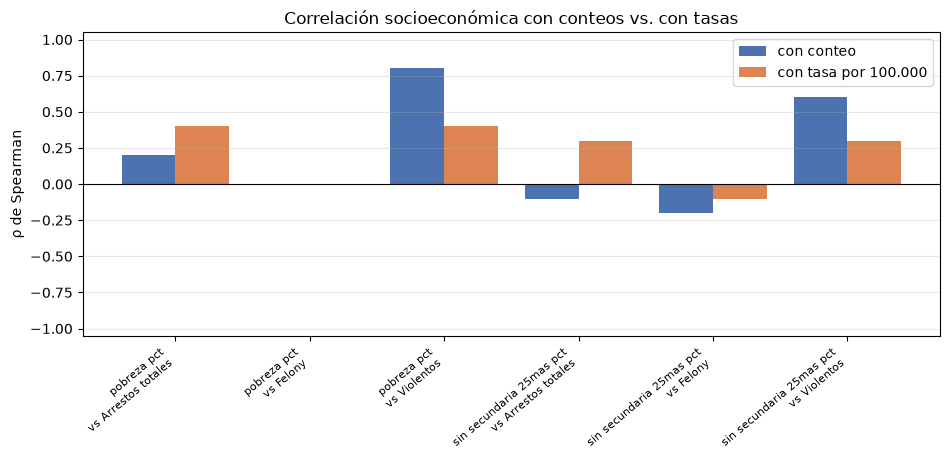

In [42]:
# Gráfica: ρ con conteo vs ρ con tasa
etiquetas = [f"{etiqueta(r.indicador_socio)}\nvs {r.indicador_seguridad}" for r in efecto_corr.itertuples()]
x = np.arange(len(efecto_corr))
fig, eje = plt.subplots(figsize=(max(9, 1.1 * len(x) + 3), 4.8))
eje.bar(x - 0.2, efecto_corr["spearman_con_conteo"], width=0.4, label="con conteo", color="#4C72B0")
eje.bar(x + 0.2, efecto_corr["spearman_con_tasa"], width=0.4, label="con tasa por 100.000", color="#DD8452")
eje.axhline(0, color="black", linewidth=0.8)
eje.set_xticks(x)
eje.set_xticklabels(etiquetas, rotation=40, ha="right", fontsize=8)
eje.set_ylim(-1.05, 1.05)
eje.set_ylabel("ρ de Spearman")
eje.set_title("Correlación socioeconómica con conteos vs. con tasas")
eje.legend()
eje.grid(axis="y", alpha=0.3)
plt.tight_layout()
fig.savefig(RESULTADOS_P78 / "P8_03_correlaciones_conteo_vs_tasa.png", dpi=150)
plt.show()

**Análisis:** La gráfica compara, para seis pares, el ρ de Spearman con el conteo (azul) y con la tasa (naranja). La normalización no tiene un efecto sistemático: en tres pares el coeficiente aumenta (pobreza–arrestos totales, de 0,2 a 0,4; sin secundaria–arrestos totales, de −0,1 a 0,3; sin secundaria–felony, de −0,2 a −0,1), en uno no cambia (pobreza–felony, 0,0 en ambos casos, por lo que no se ven barras) y en dos disminuye (pobreza–violentos, de 0,8 a 0,4; sin secundaria–violentos, de 0,6 a 0,3).

Las dos caídas, ambas en delitos violentos, muestran el riesgo de interpretar los conteos. Con conteos, la correlación de pobreza con violentos parece alta (0,8), pero al normalizar Manhattan, el distrito de menor pobreza, pasa del cuarto al segundo lugar en violentos y desordena la relación, por lo que ρ baja a 0,4. Es decir, la correlación más alta con conteos no indica una asociación más fuerte: mezcla el efecto del tamaño poblacional con el de las condiciones socioeconómicas. El único cambio de signo (sin secundaria–arrestos totales) ocurre entre valores cercanos a cero (−0,1 y 0,3), por lo que no es sustantivo.

En síntesis, la normalización modifica la magnitud de las correlaciones en la mayoría de los pares y su dirección solo en uno, sin fortalecerlas ni debilitarlas de forma general. Su importancia está en que la tasa es la base adecuada para comparar distritos de distinto tamaño, por lo que las relaciones de la pregunta 7 se interpretan con tasas y no con conteos.

## 6.5 Robustez del denominador
 
Las tasas dependen de la población residente. Se evalúan dos aspectos:
 
1. **Distancia entre distritos contiguos del ranking**: si dos tasas son casi iguales, su orden no es confiable.
2. **Escenarios de población**: se multiplica la población de un distrito por 0,8, 0,9, 1,1 y 1,2 (uno a la vez) y se observa si cambia el ranking. También se calcula cuánto tendría que variar la población para empatar con el vecino inmediato.

In [48]:
tasas0 = tabla.set_index("borough")["tasa_arrestos_100k"].sort_values(ascending=False)
arrestos0 = tabla.set_index("borough")["arrestos"]
pobl0 = tabla.set_index("borough")["poblacion"]
 
# 1. Distancia relativa entre contiguos
contiguos = pd.DataFrame({
    "borough": tasas0.index[:-1], "tasa": tasas0.values[:-1],
    "siguiente": tasas0.index[1:], "tasa_siguiente": tasas0.values[1:],
})
contiguos["diferencia_relativa_%"] = (contiguos["tasa"] - contiguos["tasa_siguiente"]) / contiguos["tasa"] * 100
print("Distancia entre distritos contiguos del ranking por tasa:")
display(contiguos.round(2))

Distancia entre distritos contiguos del ranking por tasa:


,borough,tasa,siguiente,tasa_siguiente,diferencia_relativa_%
0,Bronx,3871.93,Manhattan,3841.74,0.78
1,Manhattan,3841.74,Brooklyn,2648.28,31.07
2,Brooklyn,2648.28,Queens,2190.26,17.29
3,Queens,2190.26,Staten Island,2189.92,0.02


**Análisis:** Las diferencias relativas entre las tasas de arrestos de distritos consecutivos permite identificar que la distribución territorial presenta distintos grados de separación entre posiciones. En particular, el Bronx y Manhattan registran tasas muy similares, con una diferencia relativa de apenas 0,78 %, mientras que Queens y Staten Island presentan una diferencia de 0,02 %, lo que indica una equivalencia prácticamente completa entre ambos distritos. En contraste, las mayores distancias se observan entre Manhattan y Brooklyn (31,07 %) y entre Brooklyn y Queens (17,29 %).

Esto sugiere que el ordenamiento territorial por tasas no representa una diferenciación homogénea entre distritos. Por el contrario, se identifican segmentos con niveles relativos de arrestos similares y otros en los que existen diferencias considerablemente mayores. En consecuencia, aunque las tasas permiten controlar el efecto del tamaño poblacional sobre los conteos absolutos, la interpretación de las posiciones debe considerar la distancia efectiva entre los valores y no únicamente el lugar ocupado en el ordenamiento.

In [53]:
# 2. Escenarios de población
orden_base = list(tasas0.index)
filas = []

# Convertimos la población a float para permitir decimales
pobl0_float = pobl0.astype(float)

for dist in tasas0.index:
    for factor in (0.8, 0.9, 1.1, 1.2):
        pobl = pobl0_float.copy()
        pobl[dist] = pobl[dist] * factor

        nueva = (arrestos0 / pobl * 100_000).sort_values(ascending=False)

        filas.append({
            "distrito_modificado": dist,
            "factor_poblacion": factor,
            "nuevo_ranking": " > ".join(nueva.index),
            "cambia_ranking": list(nueva.index) != orden_base,
        })

escenarios = pd.DataFrame(filas)

escenarios.to_csv(
    RESULTADOS_P78 / "P8_escenarios_denominador.csv",
    index=False
)

print("\nRanking base:", " > ".join(orden_base))
print(f"Escenarios que cambian el ranking: {int(escenarios['cambia_ranking'].sum())} de {len(escenarios)}")

display(escenarios[escenarios["cambia_ranking"]].reset_index(drop=True))


Ranking base: Bronx > Manhattan > Brooklyn > Queens > Staten Island
Escenarios que cambian el ranking: 9 de 20


,distrito_modificado,factor_poblacion,nuevo_ranking,cambia_ranking
0,Bronx,1.1,Manhattan > Bronx > Brooklyn > Queens > Staten...,True
1,Bronx,1.2,Manhattan > Bronx > Brooklyn > Queens > Staten...,True
2,Manhattan,0.8,Manhattan > Bronx > Brooklyn > Queens > Staten...,True
3,Manhattan,0.9,Manhattan > Bronx > Brooklyn > Queens > Staten...,True
4,Queens,0.8,Bronx > Manhattan > Queens > Brooklyn > Staten...,True
5,Queens,1.1,Bronx > Manhattan > Brooklyn > Staten Island >...,True
6,Queens,1.2,Bronx > Manhattan > Brooklyn > Staten Island >...,True
7,Staten Island,0.8,Bronx > Manhattan > Staten Island > Brooklyn >...,True
8,Staten Island,0.9,Bronx > Manhattan > Brooklyn > Staten Island >...,True


**Análisis:** La tabla presenta un ejercicio de sensibilidad del ranking de tasas de arrestos frente a modificaciones hipotéticas de los denominadores poblacionales de cada borough. De los 20 escenarios evaluados, 9 (45 %) generan cambios en el ordenamiento original, mientras que los 11 restantes (55 %) conservan la clasificación inicial. Este resultado evidencia que la jerarquización territorial no es completamente estable ante variaciones en la población utilizada para calcular las tasas.

Los cambios más relevantes se presentan entre Bronx y Manhattan, que intercambian el primer lugar cuando se incrementa la población del Bronx o se reduce la de Manhattan. Este comportamiento es consistente con la reducida diferencia entre sus tasas originales. También se observa sensibilidad en las posiciones inferiores: una reducción de 20 % en la población de Queens o de Staten Island los hace superar a Brooklyn, y un aumento de 10 % o más en la población de Queens (o una reducción de 10 % o más en la de Staten Island) invierte el orden entre ambos. En ninguno de los 20 escenarios el Bronx y Manhattan dejan de ocupar las dos primeras posiciones: lo único que cambia es su orden entre sí.

Las diferencias entre algunos boroughs son sensibles a la especificación del denominador poblacional, por lo que el ranking debe interpretarse como un ordenamiento condicionado por la población de referencia y no como una jerarquía territorial invariable. No obstante, dado que los escenarios corresponden a modificaciones hipotéticas y no a estimaciones alternativas de la población real, el ejercicio no demuestra que el denominador utilizado sea inadecuado. Su utilidad consiste en identificar qué posiciones son más susceptibles a cambios.

In [45]:
# 3. Variación de población necesaria para empatar con el vecino
filas = []
for i, dist in enumerate(tasas0.index):
    fila = {"borough": dist, "tasa": tasas0[dist]}
    if i > 0:
        fila["cambio_poblacion_%_para_empatar_con_el_de_arriba"] = (tasas0[dist] / tasas0.iloc[i - 1] - 1) * 100
    if i < len(tasas0) - 1:
        fila["cambio_poblacion_%_para_empatar_con_el_de_abajo"] = (tasas0[dist] / tasas0.iloc[i + 1] - 1) * 100
    filas.append(fila)
punto_empate = pd.DataFrame(filas)
punto_empate.to_csv(RESULTADOS_P78 / "P8_punto_de_empate_poblacion.csv", index=False)
print("\nVariación porcentual de la población residente que igualaría la tasa del vecino:")
display(punto_empate.round(2))


Variación porcentual de la población residente que igualaría la tasa del vecino:


,borough,tasa,cambio_poblacion_%_para_empatar_con_el_de_abajo,cambio_poblacion_%_para_empatar_con_el_de_arriba
0,Bronx,3871.93,0.79,NaN
1,Manhattan,3841.74,45.07,-0.78
2,Brooklyn,2648.28,20.91,-31.07
3,Queens,2190.26,0.02,-17.29
4,Staten Island,2189.92,NaN,-0.02


**Análisis:** La tabla responde a la pregunta: "¿cuánto tendría que crecer o disminuir la población de un distrito para empatar con el vecino?". En primer lugar, se identifican dos pares con tasas prácticamente equivalentes: Bronx-Manhattan y Queens-Staten Island. En el primer caso, un incremento de apenas 0.79 % en la población del Bronx permitiría igualar la tasa de Manhattan, mientras que, en el segundo, un aumento de 0.02 % en la población de Queens produciría el mismo resultado respecto a Staten Island. Esto indica que las posiciones relativas de estos distritos son especialmente sensibles a pequeñas variaciones del denominador poblacional.

En contraste, las diferencias entre Manhattan y Brooklyn, así como entre Brooklyn y Queens, son considerablemente mayores. Por ejemplo, Manhattan necesitaría incrementar su población en 45.07 % para igualar la tasa de Brooklyn, mientras que Brooklyn requeriría un aumento del 20.91 % para alcanzar la tasa de Queens. Estas magnitudes sugieren que las diferencias entre dichos distritos son más pronunciadas y que su ordenamiento relativo presenta una mayor separación.

En consecuencia, se puede distinguir entre posiciones del ranking que responden a diferencias mínimas en las tasas y aquellas que presentan brechas más amplias. Por tanto, aunque el ordenamiento general permite identificar patrones de concentración territorial de los arrestos por población residente, la proximidad entre algunos distritos exige cautela al interpretar sus posiciones como diferencias sustantivas.

In [54]:
c1 = comp["arrestos"].idxmax()
t1 = comp["tasa_arrestos_100k"].idxmax()
ranking_conteo = " > ".join(comp.sort_values("arrestos", ascending=False).index)
ranking_tasa = " > ".join(comp.sort_values("tasa_arrestos_100k", ascending=False).index)
 
suben = comp[comp["cambio_posiciones"] > 0]
bajan = comp[comp["cambio_posiciones"] < 0]
descr_suben = "; ".join(f"{n} (de {int(r.rank_conteo)}.º a {int(r.rank_tasa)}.º)" for n, r in suben.iterrows()) or "ninguno"
descr_bajan = "; ".join(f"{n} (de {int(r.rank_conteo)}.º a {int(r.rank_tasa)}.º)" for n, r in bajan.iterrows()) or "ninguno"
 
mayor_conc = comp["indice_concentracion"].idxmax()
menor_conc = comp["indice_concentracion"].idxmin()
 
fila_total = tamano[tamano["indicador"] == etiqueta("arrestos")].iloc[0]
cambian_signo = efecto_corr[efecto_corr["cambia_signo"]]
min_dif = contiguos.loc[contiguos["diferencia_relativa_%"].idxmin()]
n_lider_cambia = int((resumen_rank["lider_por_conteo"] != resumen_rank["lider_por_tasa"]).sum())
 
texto_p8 = f"""
### Respuesta a la pregunta 8
 
Al normalizar los arrestos por población (tasa por 100.000 habitantes), la lectura territorial cambia de forma importante:
 
- **Ranking por conteo:** {ranking_conteo}. **Ranking por tasa:** {ranking_tasa}.
- El distrito con más arrestos en términos absolutos es **{c1}**; el de mayor tasa es **{t1}**.
- Suben al normalizar: {descr_suben}. Bajan: {descr_bajan}.
- El índice de concentración (% de arrestos / % de población) es máximo en **{mayor_conc}** ({comp.loc[mayor_conc, 'indice_concentracion']:.2f}) y mínimo en **{menor_conc}** ({comp.loc[menor_conc, 'indice_concentracion']:.2f}).
- El conteo total sigue de cerca el tamaño poblacional (ρ de Spearman población–conteo = {fila_total['spearman_poblacion_vs_conteo']:+.2f}), mientras que la tasa lo hace mucho menos (ρ = {fila_total['spearman_poblacion_vs_tasa']:+.2f}): la normalización elimina el efecto de escala.
- El líder del ranking cambia al normalizar en {n_lider_cambia} de {len(resumen_rank)} indicadores de seguridad analizados.
- En las correlaciones con pobreza y educación, el signo cambia al pasar de conteos a tasas en {len(cambian_signo)} de {len(efecto_corr)} comparaciones evaluadas.
- **Robustez:** la menor diferencia entre tasas contiguas es {min_dif['diferencia_relativa_%']:.2f} % ({min_dif['borough']} vs {min_dif['siguiente']}); el orden entre esos dos distritos no es defendible. {int(escenarios['cambia_ranking'].sum())} de {len(escenarios)} escenarios de ±10 % y ±20 % en la población de un distrito alteran el ranking.

"""
display(Markdown(texto_p8))


### Respuesta a la pregunta 8

Al normalizar los arrestos por población (tasa por 100.000 habitantes), la lectura territorial cambia de forma importante:

- **Ranking por conteo:** Brooklyn > Manhattan > Bronx > Queens > Staten Island. **Ranking por tasa:** Bronx > Manhattan > Brooklyn > Queens > Staten Island.
- El distrito con más arrestos en términos absolutos es **Brooklyn**; el de mayor tasa es **Bronx**.
- Suben al normalizar: Bronx (de 3.º a 1.º). Bajan: Brooklyn (de 1.º a 3.º).
- El índice de concentración (% de arrestos / % de población) es máximo en **Bronx** (1.32) y mínimo en **Staten Island** (0.75).
- El conteo total sigue de cerca el tamaño poblacional (ρ de Spearman población–conteo = +0.70), mientras que la tasa lo hace mucho menos (ρ = +0.10): la normalización elimina el efecto de escala.
- El líder del ranking cambia al normalizar en 6 de 7 indicadores de seguridad analizados.
- En las correlaciones con pobreza y educación, el signo cambia al pasar de conteos a tasas en 1 de 6 comparaciones evaluadas.
- **Robustez:** la menor diferencia entre tasas contiguas es 0.02 % (Queens vs Staten Island); el orden entre esos dos distritos no es defendible. 9 de 20 escenarios de ±10 % y ±20 % en la población de un distrito alteran el ranking.



## **Conclusión de la pregunta 8**

**Respuesta.** Al normalizar por población, los indicadores territoriales de seguridad **cambian de forma importante**: se pasa de responder "¿dónde hay más arrestos?" (Brooklyn) a "¿dónde es más frecuente un arresto por habitante?" (Bronx y Manhattan). La normalización elimina el efecto del tamaño poblacional, reordena a los distritos y revela dos niveles de intensidad bien diferenciados.

**Evidencia que sustenta la respuesta**

1. **Ranking de arrestos totales.** Brooklyn pasa del primer lugar por conteo (68.405) al tercero por tasa (2.648 por 100.000); el Bronx, del tercero al primero (3.872); Manhattan es segundo en ambas medidas (3.842); Queens y Staten Island conservan el cuarto y el quinto lugar (≈ 2.190).
2. **Mecanismo.** El índice de concentración (% de arrestos / % de población) es 1,32 en el Bronx y 1,31 en Manhattan, frente a 0,90 en Brooklyn y 0,75 en Queens y Staten Island. Bronx y Manhattan reúnen el 47,8 % de los arrestos con el 36,4 % de la población.
3. **Efecto del tamaño.** Los conteos siguen a la población (Pearson entre 0,58 y 0,92; ρ de Spearman = 0,70 en arrestos totales), mientras que las tasas la eliminan (Pearson entre −0,29 y 0,23; ρ = 0,10).
4. **Por tipo de arresto.** El líder cambia al normalizar en 6 de 7 indicadores: el Bronx encabeza las tasas de arrestos totales, misdemeanor, violentos, drogas y armas, y Manhattan las de felony y propiedad. Brooklyn desciende en las siete categorías. El efecto es mayor en misdemeanor y drogas (cambian los cinco distritos; ρ conteo–tasa = 0,6) y menor en armas (0,9) y propiedad (0,8).
5. **Relación con pobreza y educación.** La normalización modifica la magnitud de las correlaciones (Pearson aumenta en los seis pares; Spearman sube en tres, no cambia en uno y baja en dos) y la dirección solo en un par cercano a cero. La correlación alta con conteos en violentos (ρ = 0,8) no indica una asociación más fuerte, sino que mezcla tamaño y condiciones socioeconómicas.
6. **Robustez del denominador.** Bronx–Manhattan (0,78 %) y Queens–Staten Island (0,02 %) son empates técnicos. De 20 escenarios de ±10 % y ±20 % en la población, 9 alteran el ranking, pero el Bronx y Manhattan permanecen siempre en las dos primeras posiciones. Manhattan necesitaría un 45,1 % más de población para igualar la tasa de Brooklyn.
7. **Contraste de hipótesis.** H6, H7, H8 y H9 quedan *apoyadas*; H10 (población flotante en Manhattan) no es contrastable con los datos disponibles.

**Lectura final.** Usar solo conteos conduce a una conclusión incompleta: Brooklyn parece el distrito con más arrestos, pero no es el que tiene mayor frecuencia por habitante. Se recomienda reportar siempre la tasa junto con el conteo y presentar a Bronx–Manhattan y a Queens–Staten Island como grupos de tasas equivalentes y no como posiciones diferenciadas. Persisten dos cautelas: la tasa usa población *residente* (puede sobreestimar la intensidad en Manhattan por su población flotante) y los arrestos reflejan también la actividad policial, no solo la incidencia delictiva.

# 7. Contraste de hipótesis
 
Cada hipótesis de la sección 4 se contrasta con una salida calculada. Los criterios son operativos y están a la vista en la columna *evidencia*; el veredicto es una ayuda de lectura, no una prueba estadística (con n = 5 no la hay).

In [55]:
def rho(s, g):
    return float(corr_df[(corr_df["indicador_socio"] == s) & (corr_df["indicador_seguridad"] == g)]["spearman"].iloc[0])
 
veredictos = []
tot = "tasa_arrestos_100k"
 
# H1
r1 = rho(COL_POBREZA, tot)
v1 = "Apoyada" if r1 >= 0.6 else "Matizada" if r1 > 0 else "No apoyada"
veredictos.append(("H1", "Pobreza ↑ → tasa de arrestos ↑", v1, f"ρ({etiqueta(COL_POBREZA)}, tasa total) = {r1:+.2f}"))
 
# H2
# El signo esperado depende de si el indicador mide carencia (sin_..., menos_...) o logro educativo
def es_carencia(c):
    c = c.lower()
    return c.startswith("sin") or "_sin_" in c or "menos" in c or "analfab" in c or "deser" in c

r2 = {c: rho(c, tot) for c in COLS_EDUCACION}
signo = {c: (1 if es_carencia(c) else -1) for c in COLS_EDUCACION}
r2_orientado = {c: r2[c] * signo[c] for c in COLS_EDUCACION}   # positivo = "menos educación, más arrestos"
v2 = "Apoyada" if all(v >= 0.6 for v in r2_orientado.values()) else "Matizada" if any(v > 0 for v in r2_orientado.values()) else "No apoyada"
veredictos.append(("H2", "Menor nivel educativo → mayor tasa de arrestos", v2,
                   "; ".join(f"ρ({c}) = {r2[c]:+.2f} [{'carencia: signo esperado +' if signo[c] > 0 else 'logro: signo esperado −'}]" for c in COLS_EDUCACION)))
 
# H3
base_abs = abs(r1)
alt = {g: abs(rho(COL_POBREZA, g)) for g in ["tasa_felony_100k", "tasa_violentos_100k"]}
mejor = max(alt, key=alt.get)
dif = alt[mejor] - base_abs
v3 = "Apoyada" if dif >= 0.1 else "Sin diferencia clara" if dif > -0.1 else "No apoyada"
veredictos.append(("H3", "Más fuerte con delitos graves que con el total", v3,
                   f"|ρ| pobreza: total {base_abs:.2f}; felony {alt['tasa_felony_100k']:.2f}; violentos {alt['tasa_violentos_100k']:.2f}"))
 
# H4
cambian = resumen_loo[resumen_loo["cambia_signo"]]
v4 = "Apoyada" if len(cambian) > 0 else "No apoyada"
veredictos.append(("H4", "Alguna correlación principal cambia de signo al excluir un distrito", v4,
                   f"{len(cambian)} de {len(resumen_loo)} pares principales cambian de signo"))
 
# H5
sub = loo_df[(loo_df["distrito_excluido"] == "Manhattan") & (loo_df["indicador_seguridad"] == tot) & (loo_df["indicador_socio"].isin(COLS_EDUCACION))]
if len(sub):
    sub = sub.assign(cambio=sub["spearman_sin_distrito"] - sub["spearman_completo"])
    maxcambio = sub.loc[sub["cambio"].abs().idxmax()]
    v5 = "Apoyada" if abs(maxcambio["cambio"]) >= 0.3 else "No apoyada"
    ev5 = f"Al excluir Manhattan, ρ({maxcambio['indicador_socio']}, tasa total) pasa de {maxcambio['spearman_completo']:+.2f} a {maxcambio['spearman_sin_distrito']:+.2f}"
else:
    v5, ev5 = "No evaluable", "Sin indicadores de educación"
veredictos.append(("H5", "Manhattan es influyente en educación–arrestos", v5, ev5))
 
# H6
veredictos.append(("H6", "El líder por conteo no es el líder por tasa", "Apoyada" if c1 != t1 else "No apoyada",
                   f"Líder por conteo: {c1}; líder por tasa: {t1}"))
 
# H7
a, b = fila_total["spearman_poblacion_vs_conteo"], fila_total["spearman_poblacion_vs_tasa"]
veredictos.append(("H7", "Los conteos siguen a la población; las tasas no", "Apoyada" if (a - b) >= 0.4 else "Matizada" if a > b else "No apoyada",
                   f"ρ(población, conteo) = {a:+.2f}; ρ(población, tasa) = {b:+.2f}"))
 
# H8
n_cambia_mag = int((efecto_corr["cambio_spearman"].abs() >= 0.3).sum())
n_cambia_signo = int(efecto_corr["cambia_signo"].sum())
v8 = "Apoyada" if (n_cambia_signo > 0 or n_cambia_mag > 0) else "No apoyada"
veredictos.append(("H8", "La relación socioeconómica cambia de conteos a tasas", v8,
                   f"{n_cambia_signo} cambios de signo y {n_cambia_mag} cambios de |Δρ| ≥ 0,3 en {len(efecto_corr)} comparaciones"))
 
# H9
v9 = "Apoyada" if min_dif["diferencia_relativa_%"] < 1 else "No apoyada"
veredictos.append(("H9", "Hay dos distritos con tasas casi idénticas", v9,
                   f"Menor diferencia contigua: {min_dif['diferencia_relativa_%']:.2f} % ({min_dif['borough']} vs {min_dif['siguiente']}); "
                   f"{int(escenarios['cambia_ranking'].sum())} de {len(escenarios)} escenarios de población alteran el ranking"))
 
# H10
pm = punto_empate.set_index("borough")
if "Manhattan" in pm.index and "cambio_poblacion_%_para_empatar_con_el_de_abajo" in pm.columns \
        and not np.isnan(pm.loc["Manhattan", "cambio_poblacion_%_para_empatar_con_el_de_abajo"]):
    ev10 = f"Manhattan necesitaría +{pm.loc['Manhattan', 'cambio_poblacion_%_para_empatar_con_el_de_abajo']:.1f} % de población para empatar con el distrito inmediatamente inferior"
else:
    ev10 = "Se puede cuantificar el punto de empate en la tabla de la sección 6.5"
veredictos.append(("H10", "El denominador residente infla la tasa de Manhattan", "No contrastable", ev10 + "; falta población diurna"))
 
panel = pd.DataFrame(veredictos, columns=["ID", "Hipótesis", "Veredicto", "Evidencia"])
panel.to_csv(RESULTADOS_P78 / "panel_hipotesis_P7_P8.csv", index=False)
pd.set_option("display.max_colwidth", 200)
display(panel)

,ID,Hipótesis,Veredicto,Evidencia
0,H1,Pobreza ↑ → tasa de arrestos ↑,Matizada,"ρ(pobreza pct, tasa total) = +0.40"
1,H2,Menor nivel educativo → mayor tasa de arrestos,Matizada,ρ(sin_secundaria_25mas_pct) = +0.30 [carencia: signo esperado +]
2,H3,Más fuerte con delitos graves que con el total,Sin diferencia clara,|ρ| pobreza: total 0.40; felony 0.00; violentos 0.40
3,H4,Alguna correlación principal cambia de signo al excluir un distrito,Apoyada,4 de 4 pares principales cambian de signo
4,H5,Manhattan es influyente en educación–arrestos,Apoyada,"Al excluir Manhattan, ρ(sin_secundaria_25mas_pct, tasa total) pasa de +0.30 a +0.80"
5,H6,El líder por conteo no es el líder por tasa,Apoyada,Líder por conteo: Brooklyn; líder por tasa: Bronx
6,H7,Los conteos siguen a la población; las tasas no,Apoyada,"ρ(población, conteo) = +0.70; ρ(población, tasa) = +0.10"
7,H8,La relación socioeconómica cambia de conteos a tasas,Apoyada,"1 cambios de signo y 3 cambios de |Δρ| ≥ 0,3 en 6 comparaciones"
8,H9,Hay dos distritos con tasas casi idénticas,Apoyada,Menor diferencia contigua: 0.02 % (Queens vs Staten Island); 9 de 20 escenarios de población alteran el ranking
9,H10,El denominador residente infla la tasa de Manhattan,No contrastable,Manhattan necesitaría +45.1 % de población para empatar con el distrito inmediatamente inferior; falta población diurna


# 8. Conclusiones y limitaciones

## ¿Qué se puede afirmar?

- **Pregunta 8.** La normalización por población cambia el orden de los distritos: Brooklyn lidera el conteo de arrestos (68.405) pero es tercero en tasa (2.648 por 100.000), mientras que el Bronx pasa del tercer al primer lugar (3.872) y, junto con Manhattan (3.842), forma el grupo de mayor intensidad de arrestos por habitante. El conteo refleja el tamaño del distrito (ρ población–conteo = 0,70, frente a 0,10 con la tasa) y la tasa permite compararlos.
- **Pregunta 7.** La relación de pobreza y educación con la seguridad es **descriptiva y frágil** por tener solo cinco territorios: es positiva pero débil con arrestos totales (ρ = 0,40 y 0,30), ninguno de los 16 pares evaluados es significativo y el signo cambia al excluir el Bronx. La relación con armas es la más consistente (pobreza ρ = 0,70) y puede considerarse una hipótesis para estudios con más territorios.
- **Casos particulares.** El Bronx concentra las mayores carencias y la tasa más alta; Manhattan tiene baja pobreza y una tasa casi igual a la del Bronx, y es el distrito que más condiciona las correlaciones.
- **Robustez del ranking.** El orden entre Bronx y Manhattan (0,78 %) y entre Queens y Staten Island (0,02 %) no es defendible; sí lo es la separación entre los tres niveles de tasas (alto, intermedio y bajo).

## Lo que no se puede afirmar

- Que la pobreza o la educación **causen** más arrestos, ni que lo observado entre distritos valga para las personas (falacia ecológica).
- Que un distrito sea "más inseguro" que otro: los arrestos miden también la actividad policial.
- Que Brooklyn sea el distrito con mayor frecuencia de arrestos: lidera el volumen, no la tasa.

## Limitaciones
 
1. **n = 5.** Los p-valores por permutación tienen un mínimo de 0,017 y los coeficientes se mueven mucho al excluir un distrito. No se deben presentar como evidencia causal ni inferencial.
2. **Arrestos ≠ delitos.** Reflejan también la intensidad y las prioridades de la actividad policial; un distrito con más patrullaje registra más arrestos sin ser necesariamente más inseguro.
3. **Falacia ecológica.** Las relaciones entre agregados territoriales no se trasladan a las personas.
4. **Denominador residente.** No recoge población flotante (turistas, trabajadores, estudiantes), lo que afecta sobre todo a Manhattan.
5. **Estimaciones muestrales.** Pobreza y educación vienen de PUMS ponderado; no se propagó el error muestral.
6. **Múltiples comparaciones.** Se evaluaron varios pares; algunos coeficientes altos pueden ser azar.
7. **Un solo indicador de seguridad con territorio.** Los siniestros viales del cuaderno 02 no están desagregados por borough.

## Trabajo futuro

- Bajar a **precinto o PUMA** (más de 70 unidades) con una tabla de correspondencia; permitiría correlaciones con potencia real.
- Incorporar **población diurna** o una medida de exposición alternativa para evaluar el efecto en Manhattan.
- Añadir **errores estándar** de PUMS (réplicas de pesos) a los indicadores de pobreza y educación.
- Sumar un segundo indicador de seguridad con territorio (por ejemplo, denuncias de delitos) para no depender solo de arrestos.

In [66]:
resumen_final = {
    "anio": ANIO,
    "n_territorios": int(len(tabla)),
    "indicadores_socioeconomicos": SOCIO,
    "indicadores_seguridad_tasas": SEG_P7,
    "fuente_poblacion": fuente_pob,
    "ranking_por_conteo": ranking_conteo,
    "ranking_por_tasa": ranking_tasa,
    "panel_hipotesis": panel.to_dict(orient="records"),
    "respuesta_P7": texto_p7.strip(),
    "respuesta_P8": texto_p8.strip(),
}
p.guardar_json("resumen_P7_P8.json", resumen_final)
 
print("Archivos generados en", RESULTADOS_P78)
for archivo in sorted(Path(RESULTADOS_P78).iterdir()):
    print(" -", archivo.name)

Archivos generados en /home/estudiante/resultados_pobreza_seguridad_P7-8
 - P7_01_perfil_socioeconomico.png
 - P7_02_heatmap_correlaciones.png
 - P7_03_dispersion.png
 - P7_04_leave_one_out.png
 - P7_correlaciones.csv
 - P7_leave_one_out.csv
 - P7_resumen_leave_one_out.csv
 - P8_01_conteo_vs_tasa.png
 - P8_02_ranking_y_participacion.png
 - P8_03_correlaciones_conteo_vs_tasa.png
 - P8_cambio_ranking_por_indicador.csv
 - P8_conteos_vs_tasas.csv
 - P8_efecto_normalizacion_correlaciones.csv
 - P8_escenarios_denominador.csv
 - P8_poblacion_vs_conteo_y_tasa.csv
 - P8_punto_de_empate_poblacion.csv
 - panel_hipotesis_P7_P8.csv
 - resumen_P7_P8.json
 - tabla_territorial_integrada_P7_P8.csv
 - tabla_territorial_integrada_P7_P8.json


In [67]:
# Cierra sesión y limpia cache
arrestos_2018.unpersist()
spark.catalog.clearCache()
spark.stop()